# Model Evaluation

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

RESULT_DIR = PROJECT_ROOT / "outputs" / "results"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Result directory:", RESULT_DIR)
print("Figure directory:", FIGURE_DIR)

Project root: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification
Result directory: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\results
Figure directory: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\figures


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from src.evaluation.compare_models import (
    build_per_class_dataframe,
    build_pretraining_ablation_dataframe,
    build_summary_dataframe,
    get_best_model,
    load_model_results,
)

from src.evaluation.confusion_matrix import (
    plot_confusion_matrix,
)

from src.evaluation.metrics import (
    CLASS_NAMES,
)

In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt

PALETTE = {
    "navy": "#4E6E81",
    "blue": "#6F8FA6",
    "sage": "#8FA89A",
    "sand": "#C2AA83",
    "rose": "#B58A8A",
    "lavender": "#9A94AC",
    "slate": "#707A83",
    "light_grey": "#D9DDE1",
    "grid": "#E7E9EC",
    "text": "#30343B",
    "muted_text": "#626972",
    "background": "#FAFAFA",
}

METRIC_COLOURS = [
    "#6EA8D7", 
    "#E6A57E",  
    "#86BFA5", 
]

COMPLEXITY_COLOURS = {
    "ResNet50 Zoobot": "#65A9E0",    
    "ConvNeXT-Nano Zoobot": "#67C3A3", 
    "ConvNeXT-Nano ImageNet": "#92B7E8", 
    "VGG16": "#F0AE72", 
    "DenseNet121": "#B79BE2", 
    "ResNet50 ImageNet": "#E99B9B", 
    "SimpleCNN": "#AEB9C4",  
}

MODEL_COLOURS = {
    "ResNet50 Zoobot": "#6EA8D7",
    "ConvNeXT-Nano Zoobot": "#86BFA5",
    "ConvNeXT-Nano ImageNet": "#9CB9E2",
    "VGG16": "#E6A57E",
    "DenseNet121": "#B7A6D9",
    "ResNet50 ImageNet": "#E59A9A",
    "SimpleCNN": "#B7C0C8",
}

IMAGENET_COLOURS = [
    "#6EA8D7",
    "#86BFA5",
    "#E6A57E",
    "#B7A6D9",
]

PAIR_COLOURS = [
    "#76A9DA",
    "#8FC4A9",
]

LINE_COLOURS = {
    "ResNet50 Zoobot": "#4F92CC",
    "ConvNeXT-Nano Zoobot": "#6FB394",
    "ConvNeXT-Nano ImageNet": "#8EAFE0",
    "VGG16": "#E7A06F",
    "DenseNet121": "#A794CF",
    "ResNet50 ImageNet": "#DE8F8F",
    "SimpleCNN": "#AAB4BD",
}

HEATMAP_CMAP = "YlGnBu"

mpl.rcParams.update(
    {
        # Font
        "font.family": "DejaVu Sans",
        "font.size": 10,

        # Titles and labels
        "axes.titlesize": 13,
        "axes.titleweight": "normal",
        "axes.labelsize": 10,
        "axes.labelcolor": PALETTE["text"],

        # Tick labels
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "xtick.color": PALETTE["muted_text"],
        "ytick.color": PALETTE["muted_text"],

        # Figure appearance
        "figure.facecolor": "white",
        "axes.facecolor": "white",

        # Borders
        "axes.edgecolor": "#C9CDD2",
        "axes.linewidth": 0.7,
        "axes.spines.top": False,
        "axes.spines.right": False,

        # Grid
        "axes.grid": False,
        "grid.color": PALETTE["grid"],
        "grid.linewidth": 0.7,
        "grid.alpha": 0.75,

        # Legend
        "legend.frameon": False,
        "legend.fontsize": 9,

        # Output quality
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "savefig.facecolor": "white",
        "savefig.bbox": "tight",
    }
)

In [4]:
results = load_model_results(RESULT_DIR)

print(f"Loaded {len(results)} model result files:")

for model_name in results:
    print("-", model_name)

Loaded 7 model result files:
- convnext_nano_imagenet
- convnext_nano_zoobot
- densenet121
- resnet50_imagenet
- resnet50_zoobot
- simplecnn
- vgg16


In [5]:
summary_df = build_summary_dataframe(results)

summary_df.round(
    {
        "Accuracy": 4,
        "Macro-F1": 4,
        "Weighted-F1": 4,
        "Parameters (M)": 2,
        "Training Time (min)": 2,
        "Inference Time (s)": 3,
    }
)

,Model Key,Model,Pretraining,Accuracy,Macro-F1,Weighted-F1,Parameters,Parameters (M),Best Epoch,Training Time (min),Inference Time (s),Test Samples,Inference per Image (ms),Throughput (images/s)
0,resnet50_zoobot,ResNet50 Zoobot,Zoobot,0.8737,0.8584,0.8708,23528522,23.53,13,24.47,4.496,1774,2.534516,394.552726
1,convnext_nano_zoobot,ConvNeXT-Nano Zoobot,Zoobot,0.8726,0.8569,0.8697,14958970,14.96,4,27.66,3.188,1774,1.797174,556.429145
2,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,ImageNet,0.8393,0.8217,0.8361,14958970,14.96,14,28.11,3.168,1774,1.785711,560.001068
3,vgg16,VGG16,ImageNet,0.8315,0.8100,0.8285,134301514,134.30,13,255.73,41.129,1774,23.184507,43.132252
4,densenet121,DenseNet121,ImageNet,0.8281,0.8064,0.8234,6964106,6.96,4,155.81,19.441,1774,10.958862,91.250354
5,resnet50_imagenet,ResNet50 ImageNet,ImageNet,0.7971,0.7788,0.7956,23528522,23.53,14,22.85,4.525,1774,2.550757,392.040534
6,simplecnn,SimpleCNN,None,0.4718,0.3774,0.4356,391946,0.39,15,8.47,2.014,1774,1.135452,880.706428


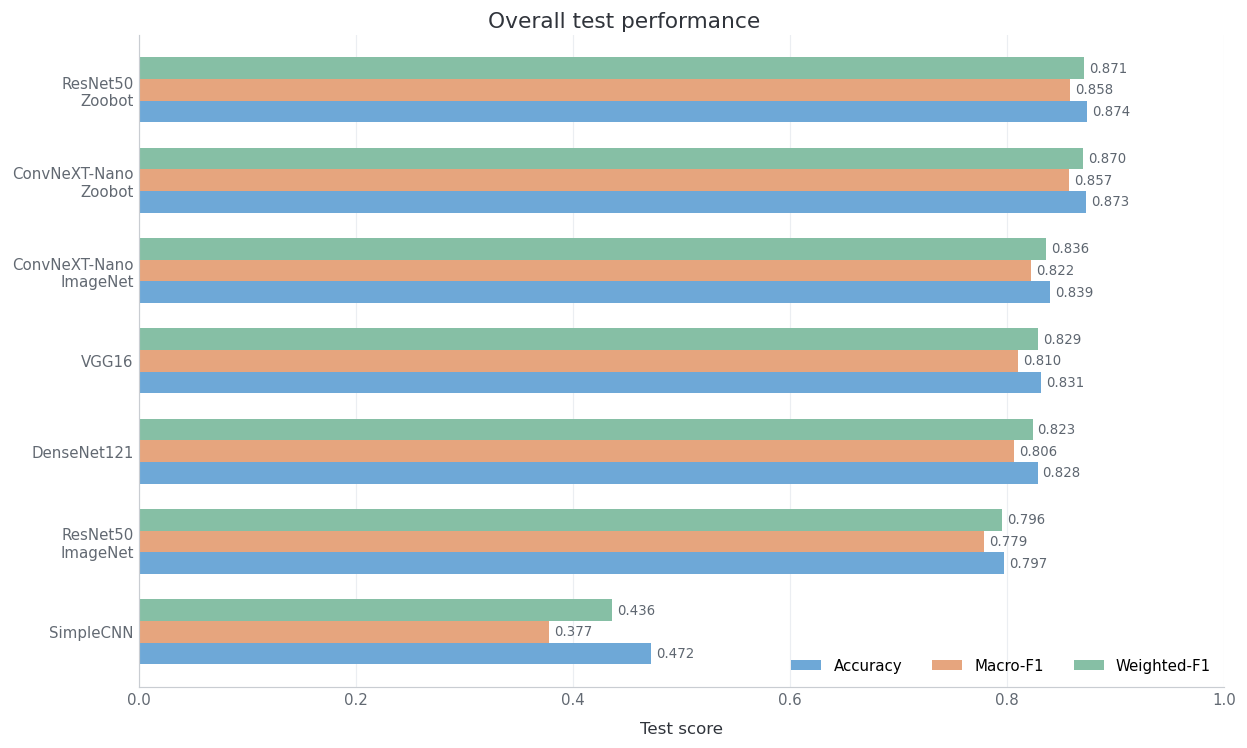

In [6]:
performance_df = (
    summary_df
    .sort_values("Macro-F1", ascending=True)
    .reset_index(drop=True)
    .copy()
)

display_names = {
    "ResNet50 Zoobot": "ResNet50\nZoobot",
    "ConvNeXT-Nano Zoobot": "ConvNeXT-Nano\nZoobot",
    "ConvNeXT-Nano ImageNet": "ConvNeXT-Nano\nImageNet",
    "ResNet50 ImageNet": "ResNet50\nImageNet",
    "DenseNet121": "DenseNet121",
    "VGG16": "VGG16",
    "SimpleCNN": "SimpleCNN",
}

performance_df["Display Model"] = (
    performance_df["Model"].map(display_names)
)

metrics_to_plot = [
    "Accuracy",
    "Macro-F1",
    "Weighted-F1",
]

axis = (
    performance_df
    .set_index("Display Model")[metrics_to_plot]
    .plot(
        kind="barh",
        figsize=(10.5, 6.8),
        width=0.72,
        color=METRIC_COLOURS,
        edgecolor="none",
    )
)

figure = axis.get_figure()
axis.set_title("")
figure.suptitle(
    "Overall test performance",
    x=0.5,
    y=0.91,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Test score",
    labelpad=8,
)
axis.set_ylabel("")
axis.set_xlim(0, 1)

axis.grid(
    axis="x",
    color="#E9EDF1",
    linewidth=0.7,
    alpha=0.9,
)

axis.set_axisbelow(True)

axis.legend(
    title=None,
    loc="lower right",
    ncol=3,
    frameon=False,
)

for container in axis.containers:
    labels = [
        f"{bar.get_width():.3f}"
        for bar in container
    ]

    axis.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=8,
        color="#5E6670",
    )

axis.tick_params(
    axis="both",
    length=0,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    FIGURE_DIR / "overall_model_performance.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [7]:
imagenet_model_keys = [
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "convnext_nano_imagenet",
]

imagenet_summary_df = summary_df[
    summary_df["Model Key"].isin(imagenet_model_keys)
].copy()

imagenet_summary_df = imagenet_summary_df.sort_values(
    "Macro-F1",
    ascending=False,
).reset_index(drop=True)

imagenet_summary_df.round(4)

,Model Key,Model,Pretraining,Accuracy,Macro-F1,Weighted-F1,Parameters,Parameters (M),Best Epoch,Training Time (min),Inference Time (s),Test Samples,Inference per Image (ms),Throughput (images/s)
0,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,ImageNet,0.8393,0.8217,0.8361,14958970,14.9590,14,28.1056,3.1679,1774,1.7857,560.0011
1,vgg16,VGG16,ImageNet,0.8315,0.8100,0.8285,134301514,134.3015,13,255.7334,41.1293,1774,23.1845,43.1323
2,densenet121,DenseNet121,ImageNet,0.8281,0.8064,0.8234,6964106,6.9641,4,155.8059,19.4410,1774,10.9589,91.2504
3,resnet50_imagenet,ResNet50 ImageNet,ImageNet,0.7971,0.7788,0.7956,23528522,23.5285,14,22.8461,4.5250,1774,2.5508,392.0405


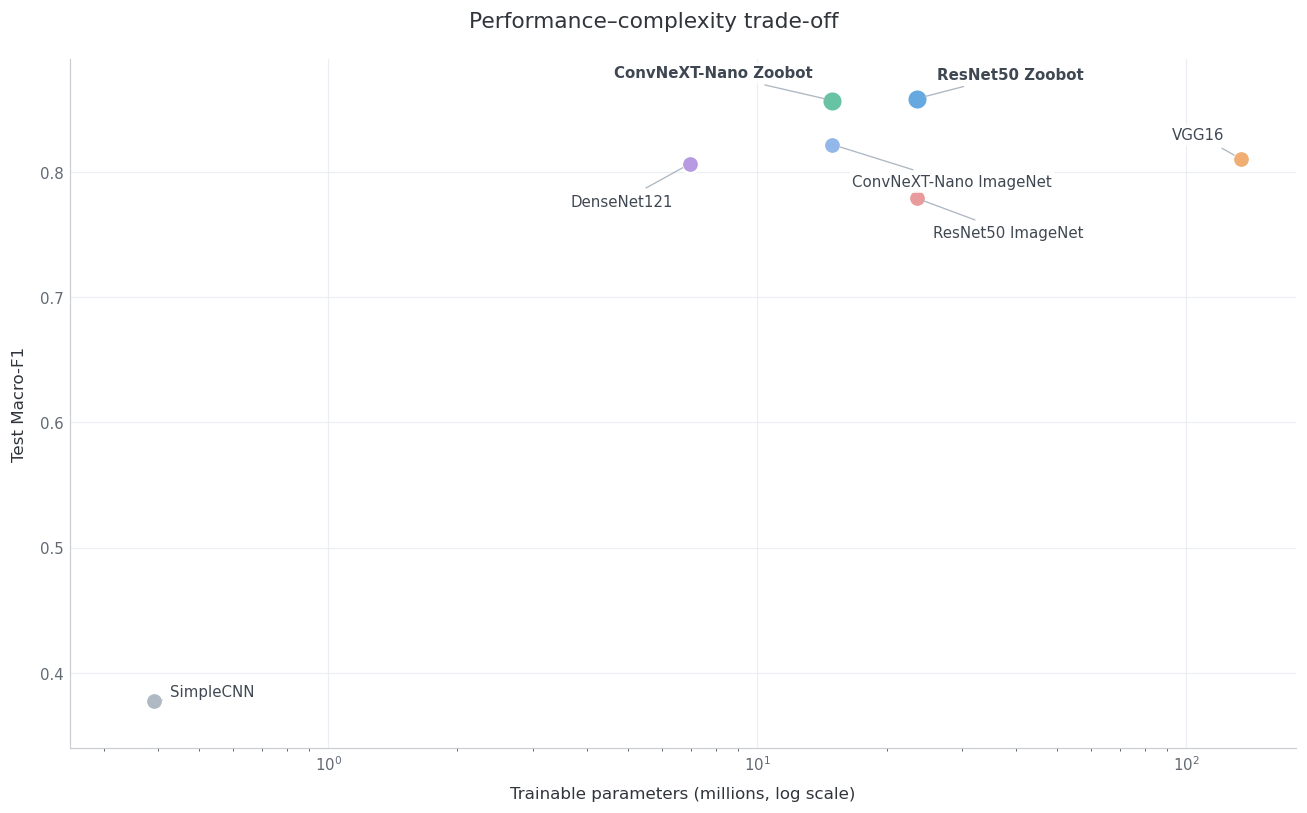

In [8]:
complexity_df = (
    summary_df
    .sort_values(
        ["Macro-F1", "Parameters (M)"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
    .copy()
)

figure, axis = plt.subplots(
    figsize=(11, 6.8),
)

annotation_settings = {
    "ResNet50 Zoobot": {
        "offset": (12, 10),
        "ha": "left",
        "va": "bottom",
    },
    "ConvNeXT-Nano Zoobot": {
        "offset": (-12, 12),
        "ha": "right",
        "va": "bottom",
    },
    "ConvNeXT-Nano ImageNet": {
        "offset": (12, -18),
        "ha": "left",
        "va": "top",
    },
    "VGG16": {
        "offset": (-10, 10),
        "ha": "right",
        "va": "bottom",
    },
    "DenseNet121": {
        "offset": (-10, -18),
        "ha": "right",
        "va": "top",
    },
    "ResNet50 ImageNet": {
        "offset": (10, -16),
        "ha": "left",
        "va": "top",
    },
    "SimpleCNN": {
        "offset": (10, 6),
        "ha": "left",
        "va": "center",
    },
}

for _, row in complexity_df.iterrows():
    model_name = row["Model"]

    is_highlight = model_name in {
        "ResNet50 Zoobot",
        "ConvNeXT-Nano Zoobot",
    }

    axis.scatter(
        row["Parameters (M)"],
        row["Macro-F1"],
        s=150 if is_highlight else 105,
        color=COMPLEXITY_COLOURS[model_name],
        edgecolor="white",
        linewidth=1.4,
        alpha=1.0,
        zorder=4,
    )

    settings = annotation_settings[model_name]

    axis.annotate(
        model_name,
        xy=(
            row["Parameters (M)"],
            row["Macro-F1"],
        ),
        xytext=settings["offset"],
        textcoords="offset points",
        ha=settings["ha"],
        va=settings["va"],
        fontsize=9,
        color="#3F4852",
        fontweight=(
            "semibold"
            if is_highlight
            else "normal"
        ),
        arrowprops={
            "arrowstyle": "-",
            "color": "#AEB8C2",
            "linewidth": 0.8,
            "shrinkA": 3,
            "shrinkB": 5,
        },
        bbox={
            "boxstyle": "round,pad=0.22",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.88,
        },
        zorder=5,
    )

axis.set_xscale("log")

axis.set_title("")

figure.suptitle(
    "Performance–complexity trade-off",
    x=0.5,
    y=0.99,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Trainable parameters (millions, log scale)",
    labelpad=8,
)
axis.set_ylabel(
    "Test Macro-F1",
    labelpad=8,
)

axis.set_xlim(0.25, 180)
axis.set_ylim(0.34, 0.89)

axis.grid(
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.tick_params(
    axis="both",
    length=0,
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "macro_f1_vs_parameters.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

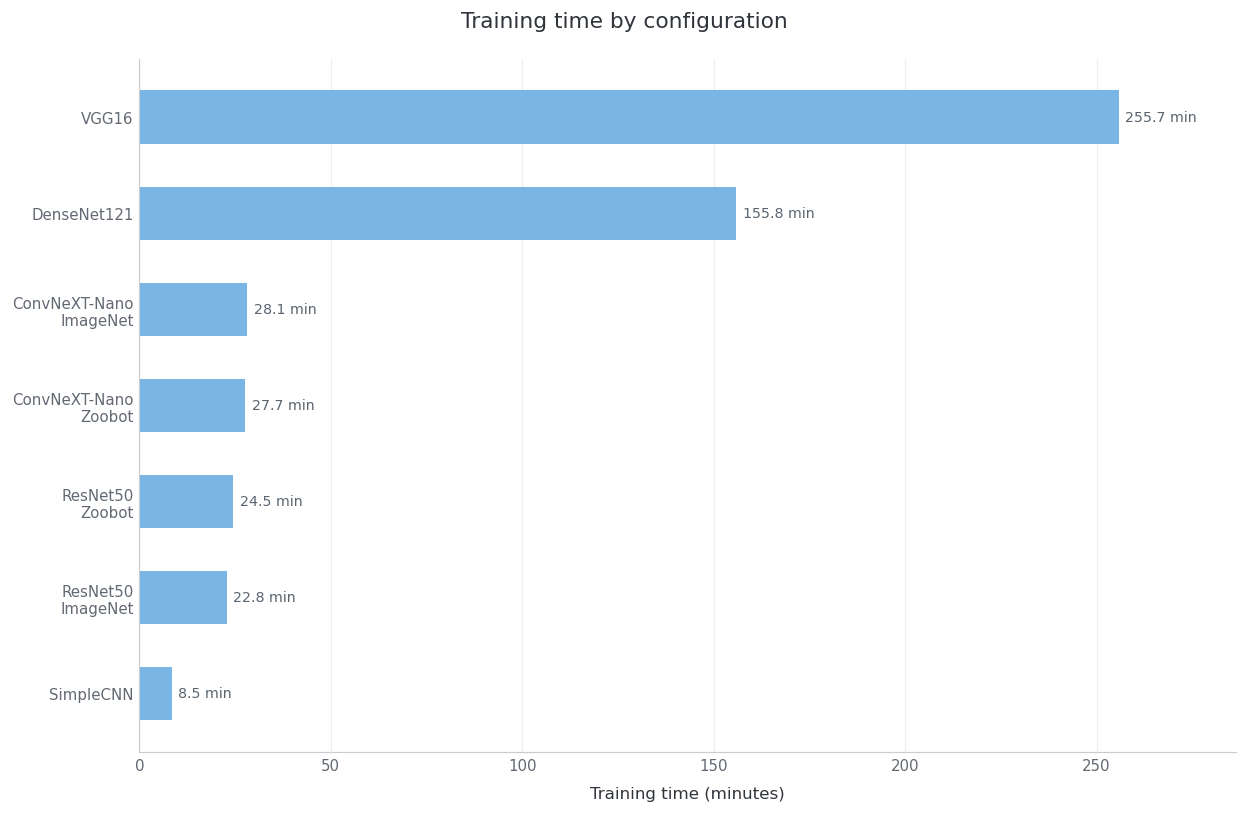

In [9]:
training_time_df = (
    summary_df
    .sort_values(
        "Training Time (min)",
        ascending=True,
    )
    .reset_index(drop=True)
    .copy()
)

training_time_df["Display Model"] = (
    training_time_df["Model"]
    .map(display_names)
)

figure, axis = plt.subplots(
    figsize=(10.5, 6.8),
)

bars = axis.barh(
    training_time_df["Display Model"],
    training_time_df["Training Time (min)"],
    color="#79B6E6",
    edgecolor="none",
    height=0.56,
)

axis.set_title("")
figure.suptitle(
    "Training time by configuration",
    x=0.5,
    y=0.99,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Training time (minutes)",
    labelpad=8,
)

axis.set_ylabel("")

axis.grid(
    axis="x",
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.bar_label(
    bars,
    labels=[
        f"{value:.1f} min"
        for value in training_time_df[
            "Training Time (min)"
        ]
    ],
    padding=4,
    fontsize=8.5,
    color="#5A6570",
)

axis.tick_params(
    axis="both",
    length=0,
)

axis.margins(x=0.12)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "training_time_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

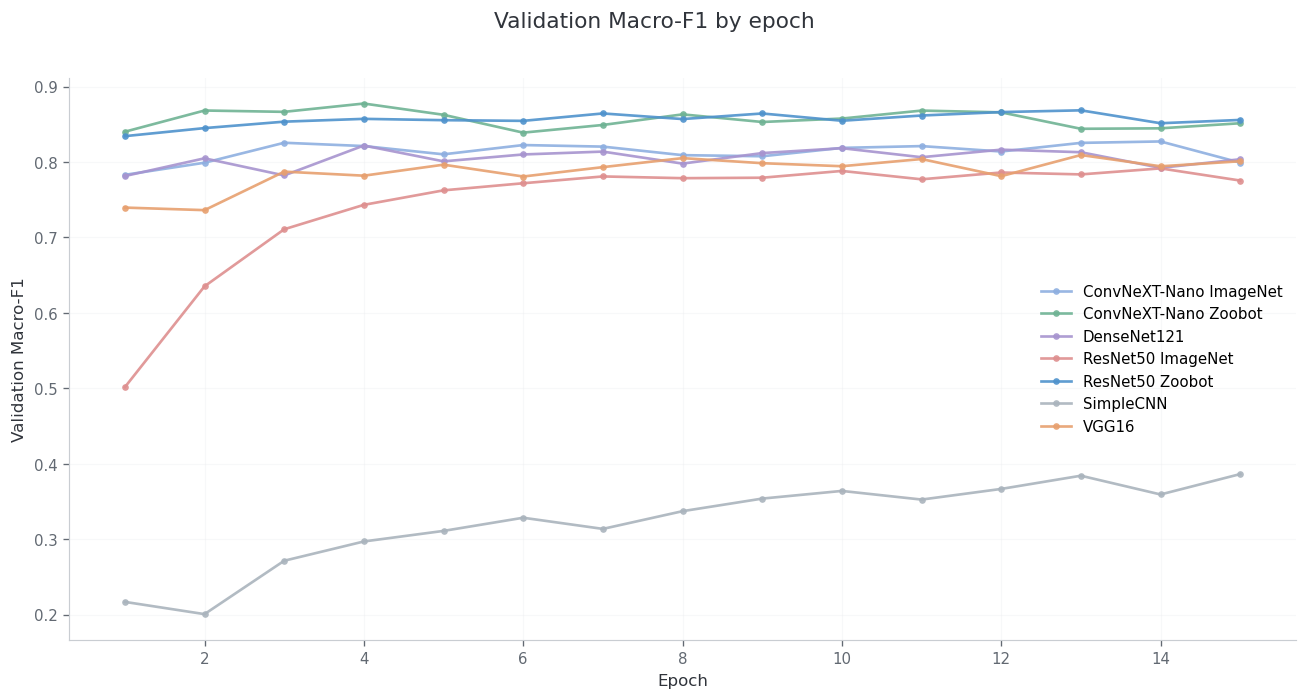

In [10]:
figure, axis = plt.subplots(figsize=(11, 6))

for model_key, result in results.items():
    history = result.get("history", {})

    epochs = history.get("epoch", [])
    val_macro_f1 = history.get("val_macro_f1", [])

    if not epochs or not val_macro_f1:
        continue

    display_name = summary_df.loc[
        summary_df["Model Key"] == model_key,
        "Model",
    ].iloc[0]

    axis.plot(
        epochs,
        val_macro_f1,
        marker="o",
        markersize=4,
        linewidth=1.6,
        color=LINE_COLOURS[display_name],
        markeredgewidth=0,
        alpha=0.9,
        label=display_name,
    )

axis.set_title("")
figure.suptitle(
    "Validation Macro-F1 by epoch",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel("Epoch")
axis.set_ylabel("Validation Macro-F1")
axis.legend()
axis.grid(alpha=0.3)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    FIGURE_DIR / "validation_macro_f1_curves.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

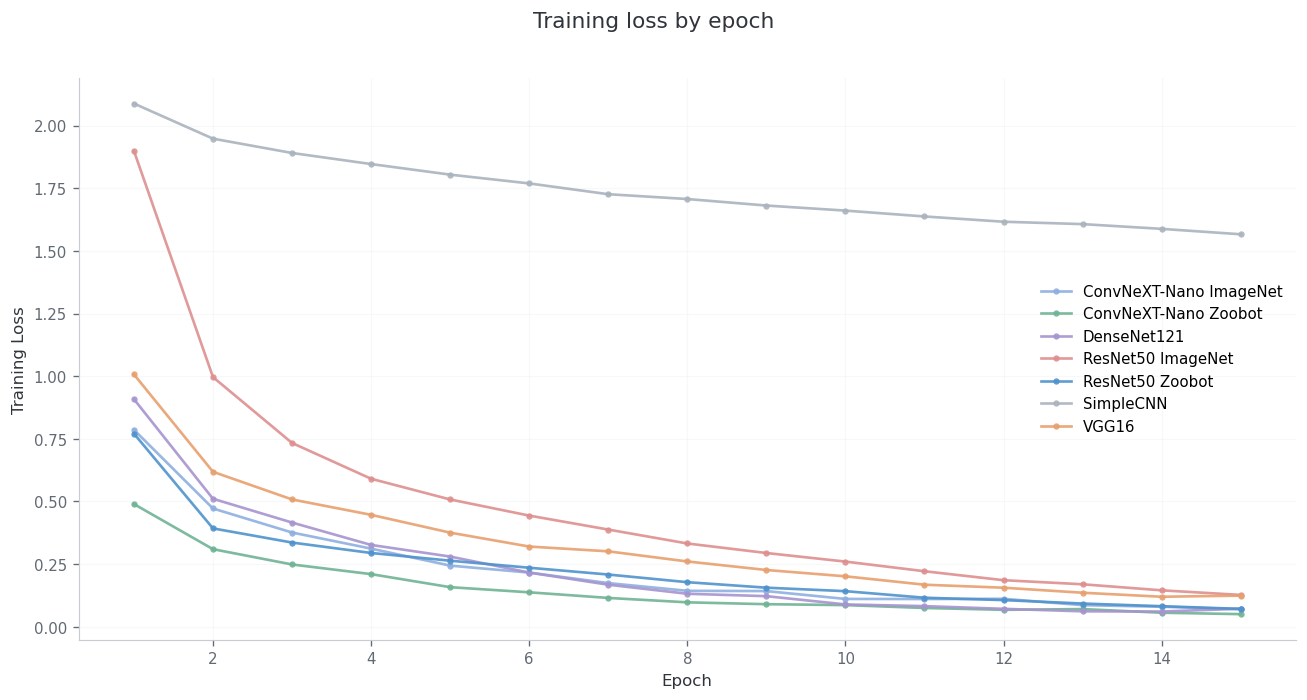

In [11]:
figure, axis = plt.subplots(figsize=(11, 6))

for model_key, result in results.items():
    history = result.get("history", {})

    epochs = history.get("epoch", [])
    train_loss = history.get("train_loss", [])

    if not epochs or not train_loss:
        continue

    display_name = summary_df.loc[
        summary_df["Model Key"] == model_key,
        "Model",
    ].iloc[0]

    axis.plot(
        epochs,
        train_loss,
        marker="o",
        markersize=3.8,
        linewidth=1.6,
        color=LINE_COLOURS[display_name],
        markeredgewidth=0,
        alpha=0.9,
        label=display_name,
    )

axis.set_title("")
figure.suptitle(
    "Training loss by epoch",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel("Epoch")
axis.set_ylabel("Training Loss")
axis.legend()
axis.grid(alpha=0.3)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    FIGURE_DIR / "training_loss_curves.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [12]:
per_class_df = build_per_class_dataframe(results)

per_class_df.head(20)

,Model Key,Model,Class,Precision,Recall,F1,Support
0,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Disturbed,0.591549,0.388889,0.469274,108
1,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Merging,0.881356,0.843243,0.861878,185
2,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Round Smooth,0.903571,0.958333,0.930147,264
3,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,In-between Smooth,0.916256,0.916256,0.916256,203
4,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Cigar-shaped Smooth,0.848485,0.823529,0.835821,34
5,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Barred Spiral,0.889474,0.824390,0.855696,205
6,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Unbarred Tight Spiral,0.701923,0.797814,0.746803,183
7,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Unbarred Loose Spiral,0.723022,0.764259,0.743068,263
8,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Edge-on w/o Bulge,0.935714,0.922535,0.929078,142
9,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Edge-on w/ Bulge,0.912371,0.946524,0.929134,187


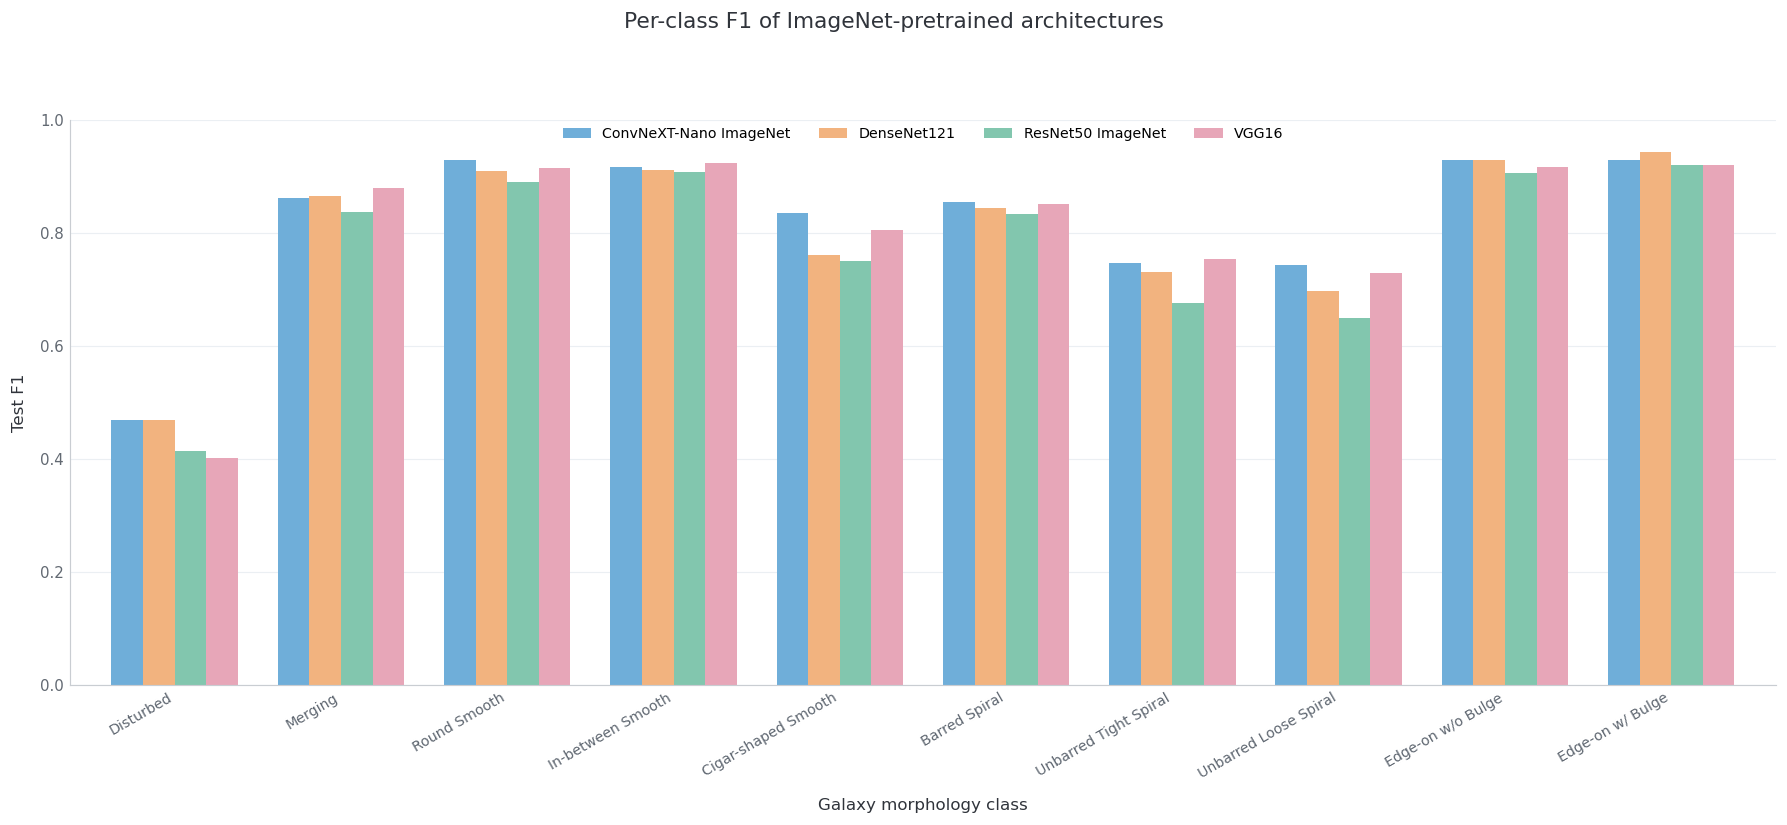

In [13]:
imagenet_per_class_models = [
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "convnext_nano_imagenet",
]

imagenet_per_class_df = per_class_df[
    per_class_df["Model Key"].isin(
        imagenet_per_class_models
    )
].copy()

imagenet_per_class_pivot = (
    imagenet_per_class_df
    .pivot(
        index="Class",
        columns="Model",
        values="F1",
    )
)

class_order = [
    "Disturbed",
    "Merging",
    "Round Smooth",
    "In-between Smooth",
    "Cigar-shaped Smooth",
    "Barred Spiral",
    "Unbarred Tight Spiral",
    "Unbarred Loose Spiral",
    "Edge-on w/o Bulge",
    "Edge-on w/ Bulge",
]

imagenet_per_class_pivot = (
    imagenet_per_class_pivot
    .reindex(class_order)
)

IMAGENET_COLOURS = [
    "#6FAED9",  # soft blue
    "#F2B37F",  # soft apricot
    "#82C6AE",  # soft mint
    "#E7A6B8",  # soft pink
]

axis = imagenet_per_class_pivot.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.76,
    color=IMAGENET_COLOURS,
    edgecolor="none",
)

figure = axis.get_figure()

axis.set_title("")

figure.suptitle(
    "Per-class F1 of ImageNet-pretrained architectures",
    x=0.5,
    y=0.975,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Galaxy morphology class",
    labelpad=10,
)

axis.set_ylabel(
    "Test F1",
    labelpad=8,
)

axis.set_ylim(0, 1)

axis.grid(
    axis="y",
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.tick_params(
    axis="x",
    rotation=30,
    length=0,
)

axis.tick_params(
    axis="y",
    length=0,
)

for label in axis.get_xticklabels():
    label.set_horizontalalignment("right")
    label.set_color("#5E6670")
    label.set_fontsize(8.5)

axis.legend(
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=4,
    frameon=False,
    fontsize=8.5,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.92]
)

plt.savefig(
    FIGURE_DIR / "imagenet_per_class_f1.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [14]:
if not per_class_df.empty:
    hardest_classes_df = (
        per_class_df
        .sort_values(
            ["Model", "F1"],
            ascending=[True, True],
        )
        .groupby("Model")
        .head(3)
    )

    hardest_classes_df[
        [
            "Model",
            "Class",
            "Precision",
            "Recall",
            "F1",
            "Support",
        ]
    ].round(4)

In [15]:
pretraining_ablation_df = (
    build_pretraining_ablation_dataframe(results)
)

if pretraining_ablation_df.empty:
    print(
        "The ImageNet and Zoobot model pairs "
        "have not all been trained yet."
    )
else:
    display(pretraining_ablation_df.round(4))

,Architecture,ImageNet Accuracy,Zoobot Accuracy,Accuracy Difference,ImageNet Macro-F1,Zoobot Macro-F1,Macro-F1 Difference
0,ResNet50,0.7971,0.8737,0.0767,0.7788,0.8584,0.0796
1,ConvNeXT-Nano,0.8393,0.8726,0.0333,0.8217,0.8569,0.0352


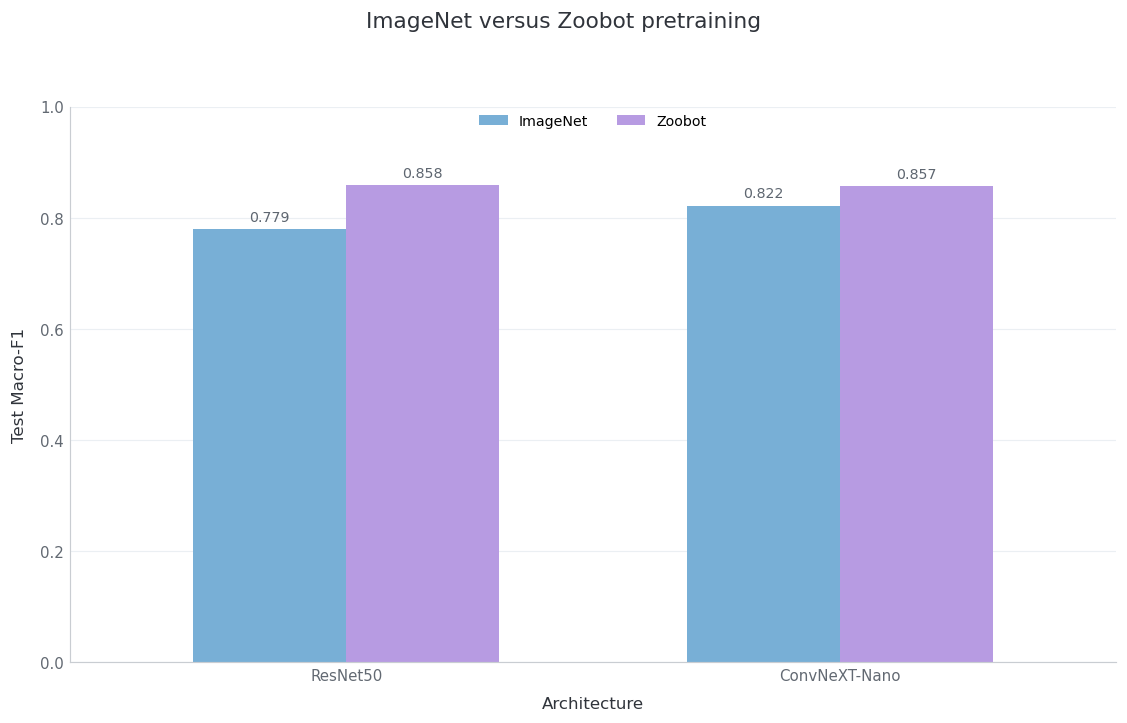

In [16]:
PRETRAINING_COLOURS = [
    "#78AFD6",  # ImageNet: soft blue
    "#B79BE2",  # Zoobot: soft pink
]

axis = pretraining_ablation_df.plot(
    x="Architecture",
    y=[
        "ImageNet Macro-F1",
        "Zoobot Macro-F1",
    ],
    kind="bar",
    figsize=(9.5, 6.2),
    width=0.62,
    color=PRETRAINING_COLOURS,
    edgecolor="none",
)

figure = axis.get_figure()

axis.set_title("")

figure.suptitle(
    "ImageNet versus Zoobot pretraining",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Architecture",
    labelpad=8,
)

axis.set_ylabel(
    "Test Macro-F1",
    labelpad=8,
)

axis.set_ylim(0, 1)

axis.tick_params(
    axis="x",
    rotation=0,
    length=0,
)

axis.tick_params(
    axis="y",
    length=0,
)

axis.grid(
    axis="y",
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.legend(
    title=None,
    labels=[
        "ImageNet",
        "Zoobot",
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
    fontsize=8.5,
)

for container in axis.containers:
    axis.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8.5,
        color="#5E6670",
    )

plt.tight_layout(
    rect=[0, 0, 1, 0.92]
)

plt.savefig(
    FIGURE_DIR / "imagenet_vs_zoobot.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [17]:
pretraining_gain_df = (
    per_class_df[
        per_class_df["Model Key"].isin(
            [
                "resnet50_imagenet",
                "resnet50_zoobot",
                "convnext_nano_imagenet",
                "convnext_nano_zoobot",
            ]
        )
    ]
    .pivot(
        index="Class",
        columns="Model Key",
        values="F1",
    )
)

pretraining_gain_df = pd.DataFrame(
    {
        "ResNet50 Zoobot Gain": (
            pretraining_gain_df["resnet50_zoobot"]
            - pretraining_gain_df["resnet50_imagenet"]
        ),
        "ConvNeXT-Nano Zoobot Gain": (
            pretraining_gain_df["convnext_nano_zoobot"]
            - pretraining_gain_df["convnext_nano_imagenet"]
        ),
    }
)

pretraining_gain_df = (
    pretraining_gain_df
    .reindex(class_order)
)

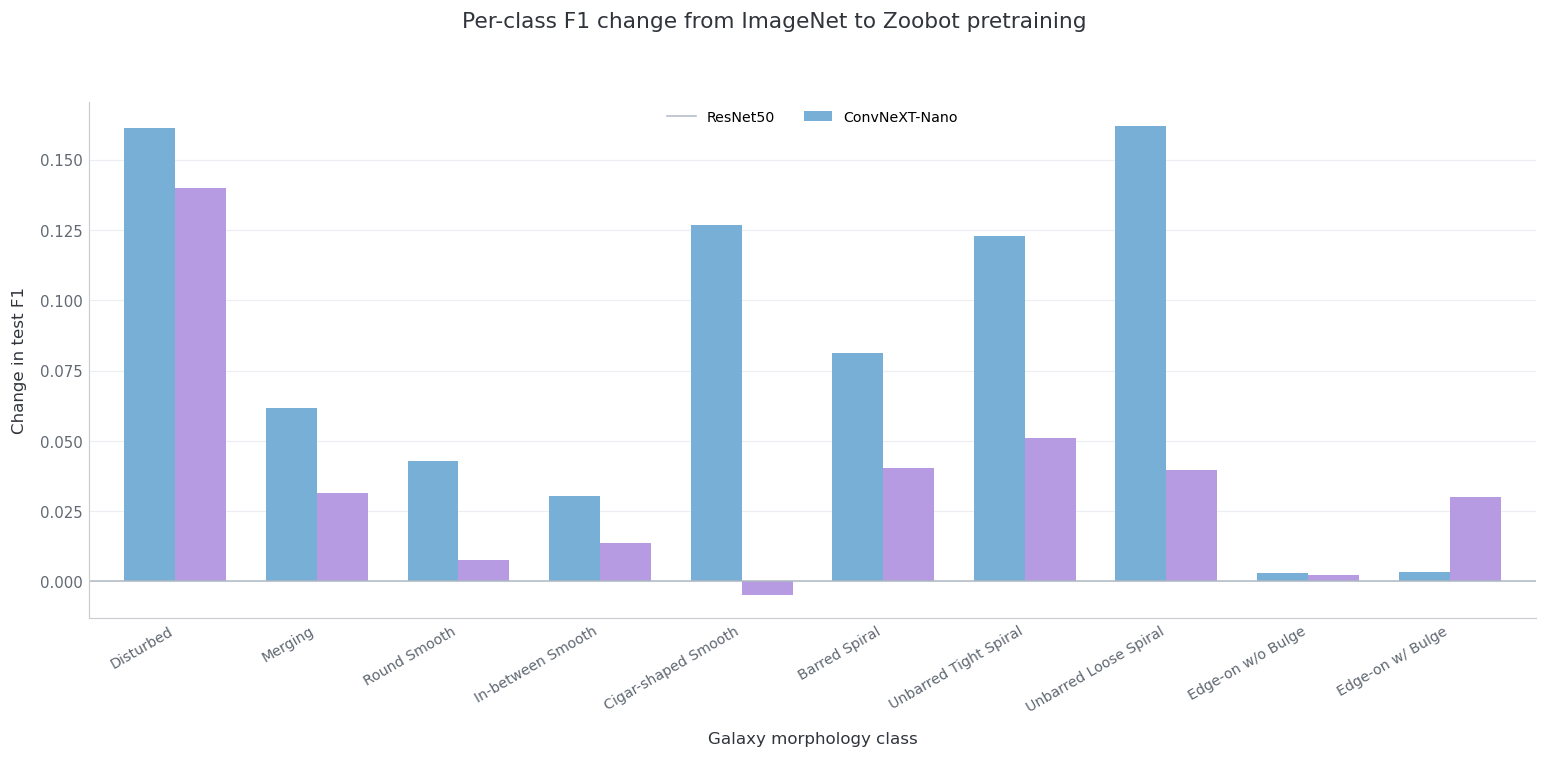

,ResNet50 Zoobot Gain,ConvNeXT-Nano Zoobot Gain
Class,,
Disturbed,0.1611,0.1399
Merging,0.0616,0.0314
Round Smooth,0.0430,0.0075
In-between Smooth,0.0304,0.0137
Cigar-shaped Smooth,0.1267,-0.0047
Barred Spiral,0.0812,0.0403
Unbarred Tight Spiral,0.1230,0.0512
Unbarred Loose Spiral,0.1621,0.0397
Edge-on w/o Bulge,0.0032,0.0024


In [ ]:
GAIN_COLOURS = [
    "#78AFD6",  # ResNet50
    "#B79BE2",  # ConvNeXT-Nano
]

axis = pretraining_gain_df.plot(
    kind="bar",
    figsize=(13, 6.5),
    width=0.72,
    color=GAIN_COLOURS,
    edgecolor="none",
)

figure = axis.get_figure()

axis.set_title("")

figure.suptitle(
    "Per-class F1 change from ImageNet to Zoobot pretraining",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Galaxy morphology class",
    labelpad=10,
)

axis.set_ylabel(
    "Change in test F1",
    labelpad=8,
)

axis.axhline(
    y=0,
    color="#AEB8C2",
    linewidth=0.9,
    zorder=1,
)

axis.grid(
    axis="y",
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.tick_params(
    axis="x",
    rotation=30,
    length=0,
)

axis.tick_params(
    axis="y",
    length=0,
)

for label in axis.get_xticklabels():
    label.set_horizontalalignment("right")
    label.set_color("#5E6670")
    label.set_fontsize(8.5)

axis.legend(
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
    fontsize=8.5,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.92]
)

plt.savefig(
    FIGURE_DIR / "zoobot_per_class_f1_gain.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

pretraining_gain_df.round(4)

In [19]:
if not summary_df.empty:
    best_model_row = get_best_model(summary_df)

    best_model_key = best_model_row["Model Key"]
    best_model_name = best_model_row["Model"]

    print("Current best model:", best_model_name)
    print("Macro-F1:", round(best_model_row["Macro-F1"], 4))

Current best model: ResNet50 Zoobot
Macro-F1: 0.8584


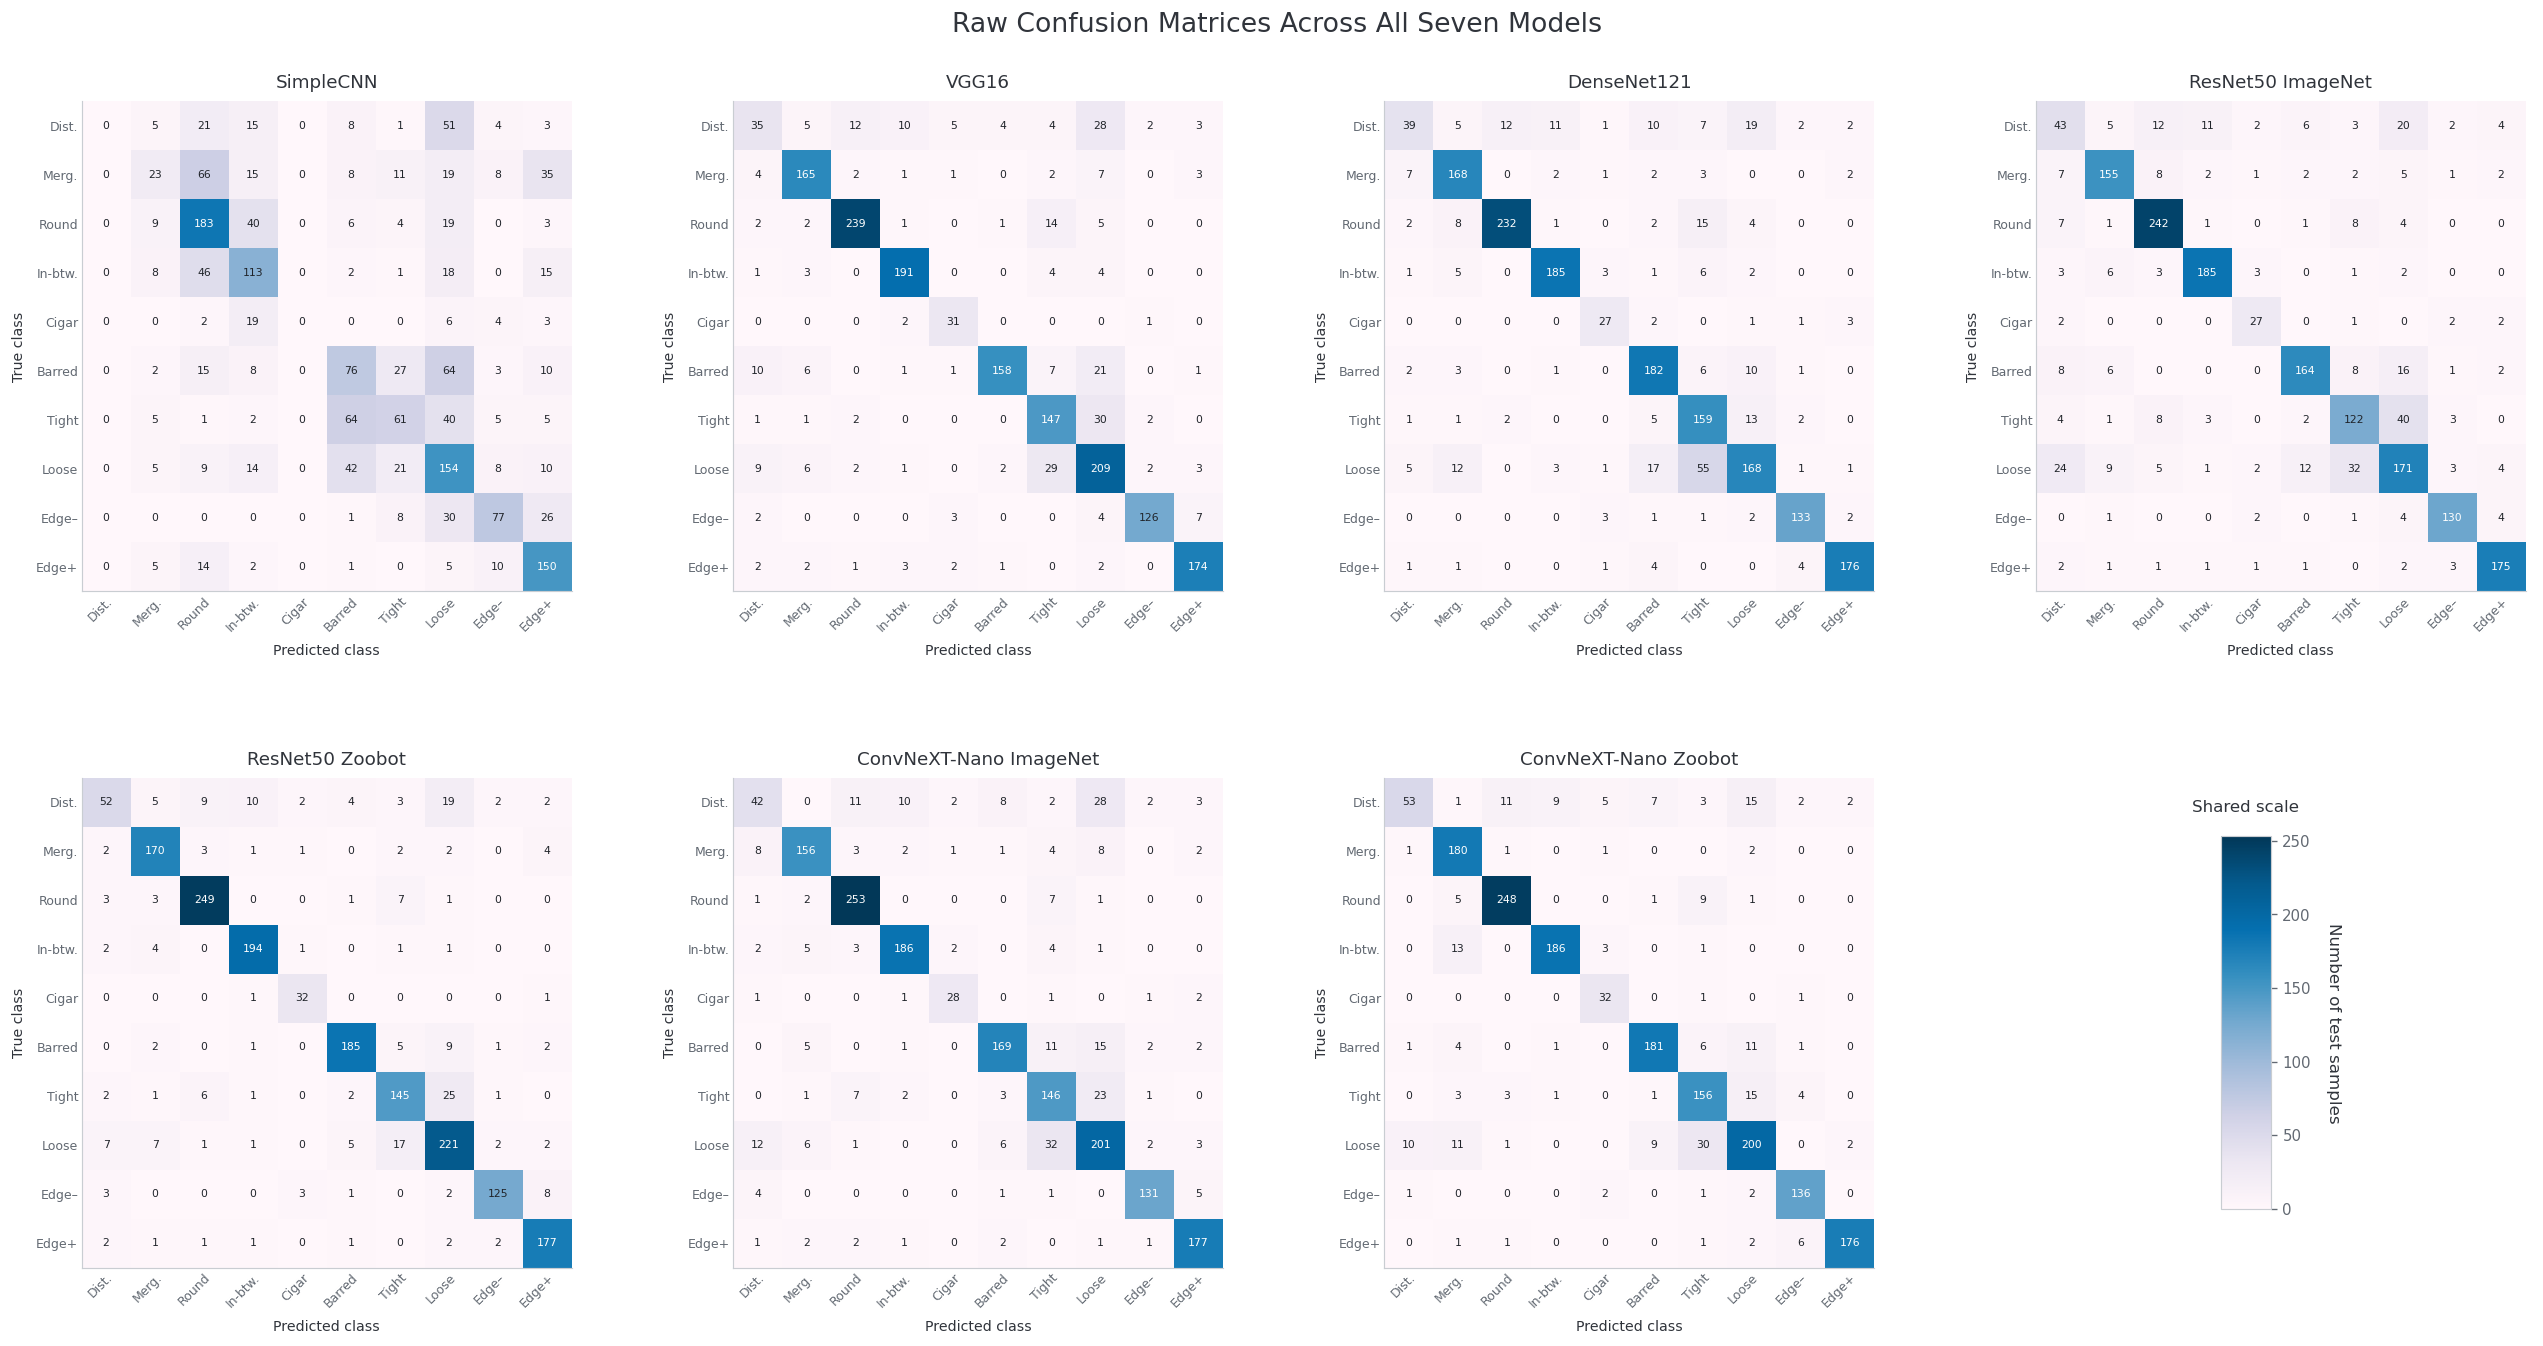

Saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\figures\all_models_raw_confusion_matrices.png


In [20]:
ALL_MODEL_KEYS = [
    "simplecnn",
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "resnet50_zoobot",
    "convnext_nano_imagenet",
    "convnext_nano_zoobot",
]

ALL_MODEL_DISPLAY_NAMES = {
    "simplecnn": "SimpleCNN",
    "vgg16": "VGG16",
    "densenet121": "DenseNet121",
    "resnet50_imagenet": "ResNet50 ImageNet",
    "resnet50_zoobot": "ResNet50 Zoobot",
    "convnext_nano_imagenet": "ConvNeXT-Nano ImageNet",
    "convnext_nano_zoobot": "ConvNeXT-Nano Zoobot",
}

SHORT_CLASS_NAMES = [
    "Dist.",
    "Merg.",
    "Round",
    "In-btw.",
    "Cigar",
    "Barred",
    "Tight",
    "Loose",
    "Edge–",
    "Edge+",
]


# Require all seven model results.
missing_models = [
    model_key
    for model_key in ALL_MODEL_KEYS
    if model_key not in results
]

if missing_models:
    raise ValueError(
        "Missing required model results: "
        + ", ".join(missing_models)
    )


# Read and validate matrices.
raw_matrices = {}

expected_shape = (
    len(CLASS_NAMES),
    len(CLASS_NAMES),
)

for model_key in ALL_MODEL_KEYS:
    if "confusion_matrix" not in results[model_key]:
        raise KeyError(
            f"Missing confusion_matrix for {model_key}."
        )

    matrix = np.asarray(
        results[model_key]["confusion_matrix"],
        dtype=float,
    )

    if matrix.shape != expected_shape:
        raise ValueError(
            f"{model_key} has confusion matrix shape "
            f"{matrix.shape}; expected {expected_shape}."
        )

    raw_matrices[model_key] = matrix


global_max = max(
    matrix.max()
    for matrix in raw_matrices.values()
)


# Create 2 × 4 layout.
figure, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 11.5),
)

axes = axes.flatten()

image = None


for axis, model_key in zip(
    axes[:7],
    ALL_MODEL_KEYS,
):
    matrix = raw_matrices[model_key]

    image = axis.imshow(
        matrix,
        cmap="PuBu",
        interpolation="nearest",
        vmin=0,
        vmax=global_max,
        aspect="equal",
    )

    axis.set_box_aspect(1)

    axis.set_title(
        ALL_MODEL_DISPLAY_NAMES[model_key],
        fontsize=11,
        fontweight="normal",
        color="#30343B",
        pad=8,
    )

    axis.set_xticks(
        np.arange(len(SHORT_CLASS_NAMES))
    )

    axis.set_yticks(
        np.arange(len(SHORT_CLASS_NAMES))
    )

    axis.set_xticklabels(
        SHORT_CLASS_NAMES,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
        fontsize=7.5,
    )

    axis.set_yticklabels(
        SHORT_CLASS_NAMES,
        fontsize=7.5,
    )

    axis.set_xlabel(
        "Predicted class",
        fontsize=8.5,
        labelpad=6,
    )

    axis.set_ylabel(
        "True class",
        fontsize=8.5,
        labelpad=6,
    )

    axis.tick_params(
        axis="both",
        length=0,
        pad=2,
    )

    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            value = matrix[
                row_index,
                column_index
            ]

            axis.text(
                column_index,
                row_index,
                f"{int(value)}",
                ha="center",
                va="center",
                fontsize=6.5,
                color=(
                    "white"
                    if value > global_max * 0.5
                    else "#20242A"
                ),
            )


# Use the eighth panel only for the colorbar.
colorbar_panel = axes[7]
colorbar_panel.axis("off")

colorbar_axis = colorbar_panel.inset_axes(
    [0.38, 0.12, 0.10, 0.76]
)

colorbar = figure.colorbar(
    image,
    cax=colorbar_axis,
)

colorbar.set_label(
    "Number of test samples",
    rotation=270,
    labelpad=18,
    fontsize=10,
)

colorbar_panel.text(
    0.43,
    0.94,
    "Shared scale",
    ha="center",
    va="center",
    fontsize=10,
    color="#30343B",
)


figure.suptitle(
    "Raw Confusion Matrices Across All Seven Models",
    fontsize=16,
    fontweight="normal",
    color="#30343B",
    y=0.985,
)

figure.subplots_adjust(
    left=0.045,
    right=0.975,
    top=0.92,
    bottom=0.075,
    wspace=0.30,
    hspace=0.38,
)


raw_output_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "all_models_raw_confusion_matrices.png"
)

raw_output_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

figure.savefig(
    raw_output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved to: {raw_output_path}")

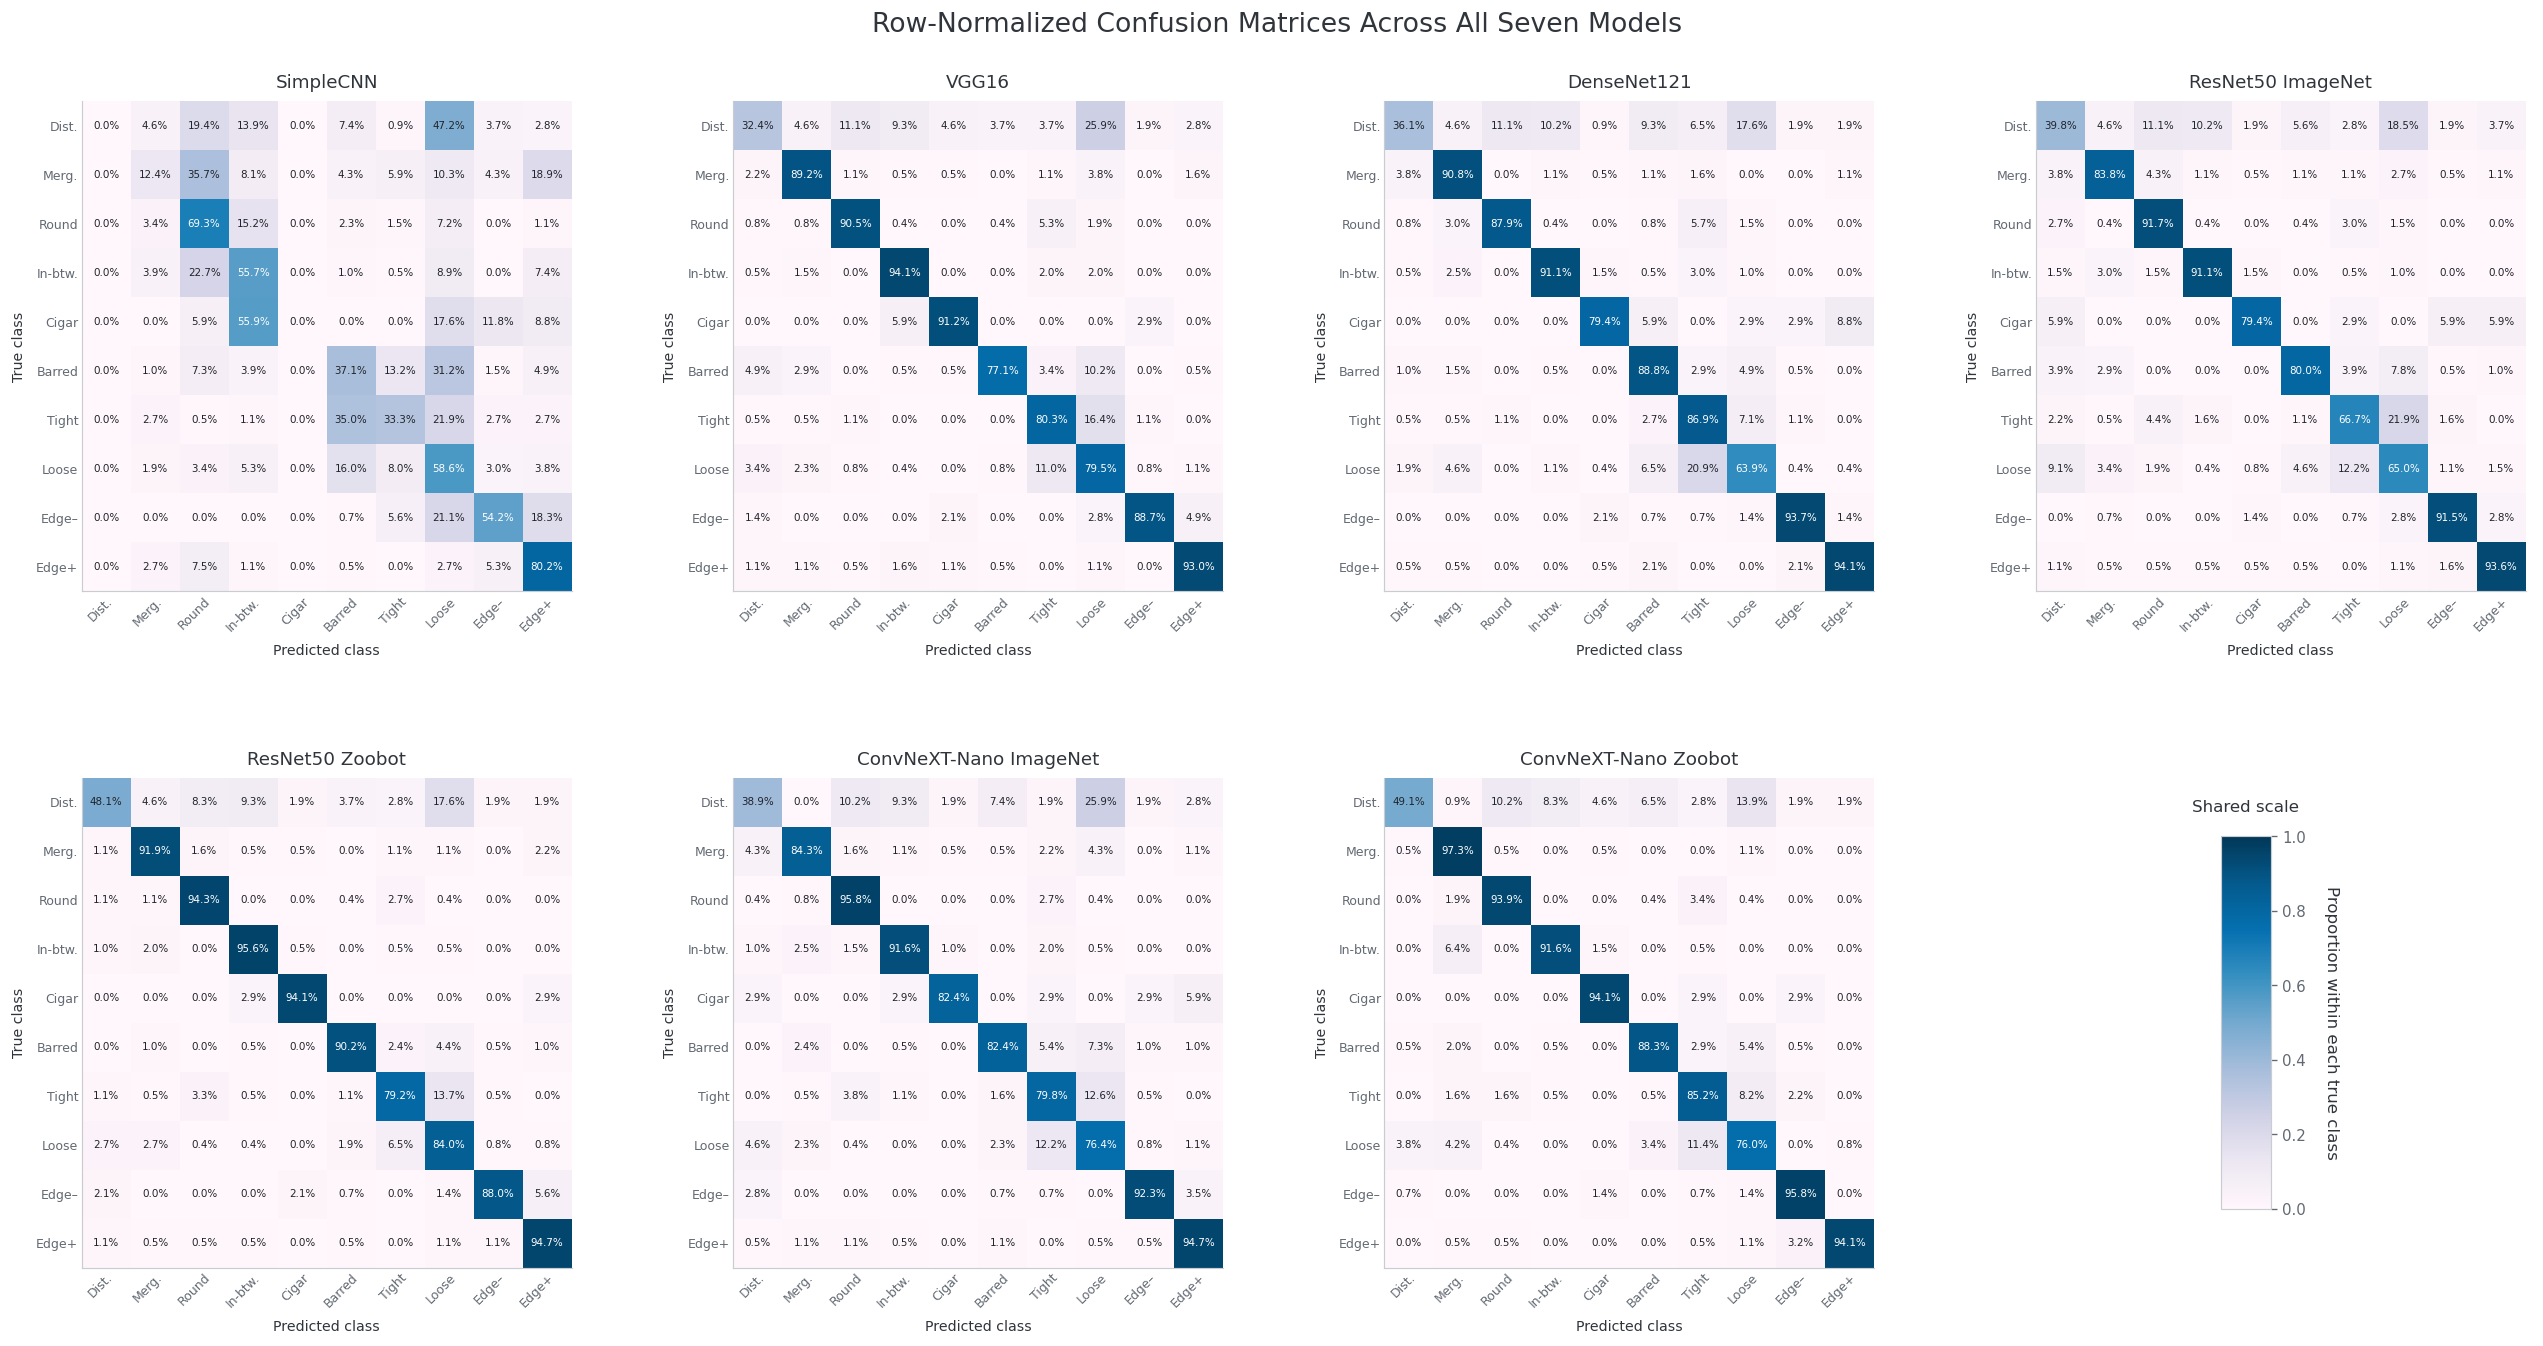

Saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\figures\all_models_normalized_confusion_matrices.png


In [21]:
ALL_MODEL_KEYS = [
    "simplecnn",
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "resnet50_zoobot",
    "convnext_nano_imagenet",
    "convnext_nano_zoobot",
]

ALL_MODEL_DISPLAY_NAMES = {
    "simplecnn": "SimpleCNN",
    "vgg16": "VGG16",
    "densenet121": "DenseNet121",
    "resnet50_imagenet": "ResNet50 ImageNet",
    "resnet50_zoobot": "ResNet50 Zoobot",
    "convnext_nano_imagenet": "ConvNeXT-Nano ImageNet",
    "convnext_nano_zoobot": "ConvNeXT-Nano Zoobot",
}

SHORT_CLASS_NAMES = [
    "Dist.",
    "Merg.",
    "Round",
    "In-btw.",
    "Cigar",
    "Barred",
    "Tight",
    "Loose",
    "Edge–",
    "Edge+",
]


# Require all seven model results.
missing_models = [
    model_key
    for model_key in ALL_MODEL_KEYS
    if model_key not in results
]

if missing_models:
    raise ValueError(
        "Missing required model results: "
        + ", ".join(missing_models)
    )


# Read, validate and normalize matrices by true-class row.
normalized_matrices = {}

expected_shape = (
    len(CLASS_NAMES),
    len(CLASS_NAMES),
)

for model_key in ALL_MODEL_KEYS:
    if "confusion_matrix" not in results[model_key]:
        raise KeyError(
            f"Missing confusion_matrix for {model_key}."
        )

    raw_matrix = np.asarray(
        results[model_key]["confusion_matrix"],
        dtype=float,
    )

    if raw_matrix.shape != expected_shape:
        raise ValueError(
            f"{model_key} has confusion matrix shape "
            f"{raw_matrix.shape}; expected {expected_shape}."
        )

    row_totals = raw_matrix.sum(
        axis=1,
        keepdims=True,
    )

    if np.any(row_totals == 0):
        empty_rows = np.where(
            row_totals.squeeze() == 0
        )[0]

        raise ValueError(
            f"{model_key} contains empty true-class rows: "
            f"{empty_rows.tolist()}."
        )

    normalized_matrices[model_key] = (
        raw_matrix / row_totals
    )


# Create 2 × 4 layout.
figure, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 11.5),
)

axes = axes.flatten()

image = None


for axis, model_key in zip(
    axes[:7],
    ALL_MODEL_KEYS,
):
    matrix = normalized_matrices[model_key]

    image = axis.imshow(
        matrix,
        cmap="PuBu",
        interpolation="nearest",
        vmin=0,
        vmax=1,
        aspect="equal",
    )

    axis.set_box_aspect(1)

    axis.set_title(
        ALL_MODEL_DISPLAY_NAMES[model_key],
        fontsize=11,
        fontweight="normal",
        color="#30343B",
        pad=8,
    )

    axis.set_xticks(
        np.arange(len(SHORT_CLASS_NAMES))
    )

    axis.set_yticks(
        np.arange(len(SHORT_CLASS_NAMES))
    )

    axis.set_xticklabels(
        SHORT_CLASS_NAMES,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
        fontsize=7.5,
    )

    axis.set_yticklabels(
        SHORT_CLASS_NAMES,
        fontsize=7.5,
    )

    axis.set_xlabel(
        "Predicted class",
        fontsize=8.5,
        labelpad=6,
    )

    axis.set_ylabel(
        "True class",
        fontsize=8.5,
        labelpad=6,
    )

    axis.tick_params(
        axis="both",
        length=0,
        pad=2,
    )

    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            value = matrix[
                row_index,
                column_index
            ]

            axis.text(
                column_index,
                row_index,
                f"{value:.1%}",
                ha="center",
                va="center",
                fontsize=6.2,
                color=(
                    "white"
                    if value > 0.5
                    else "#20242A"
                ),
            )


colorbar_panel = axes[7]
colorbar_panel.axis("off")

colorbar_axis = colorbar_panel.inset_axes(
    [0.38, 0.12, 0.10, 0.76]
)

colorbar = figure.colorbar(
    image,
    cax=colorbar_axis,
)

colorbar.set_label(
    "Proportion within each true class",
    rotation=270,
    labelpad=20,
    fontsize=10,
)

colorbar_panel.text(
    0.43,
    0.94,
    "Shared scale",
    ha="center",
    va="center",
    fontsize=10,
    color="#30343B",
)


figure.suptitle(
    "Row-Normalized Confusion Matrices Across All Seven Models",
    fontsize=16,
    fontweight="normal",
    color="#30343B",
    y=0.985,
)

figure.subplots_adjust(
    left=0.045,
    right=0.975,
    top=0.92,
    bottom=0.075,
    wspace=0.30,
    hspace=0.38,
)


normalized_output_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "all_models_normalized_confusion_matrices.png"
)

normalized_output_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

figure.savefig(
    normalized_output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved to: {normalized_output_path}"
)

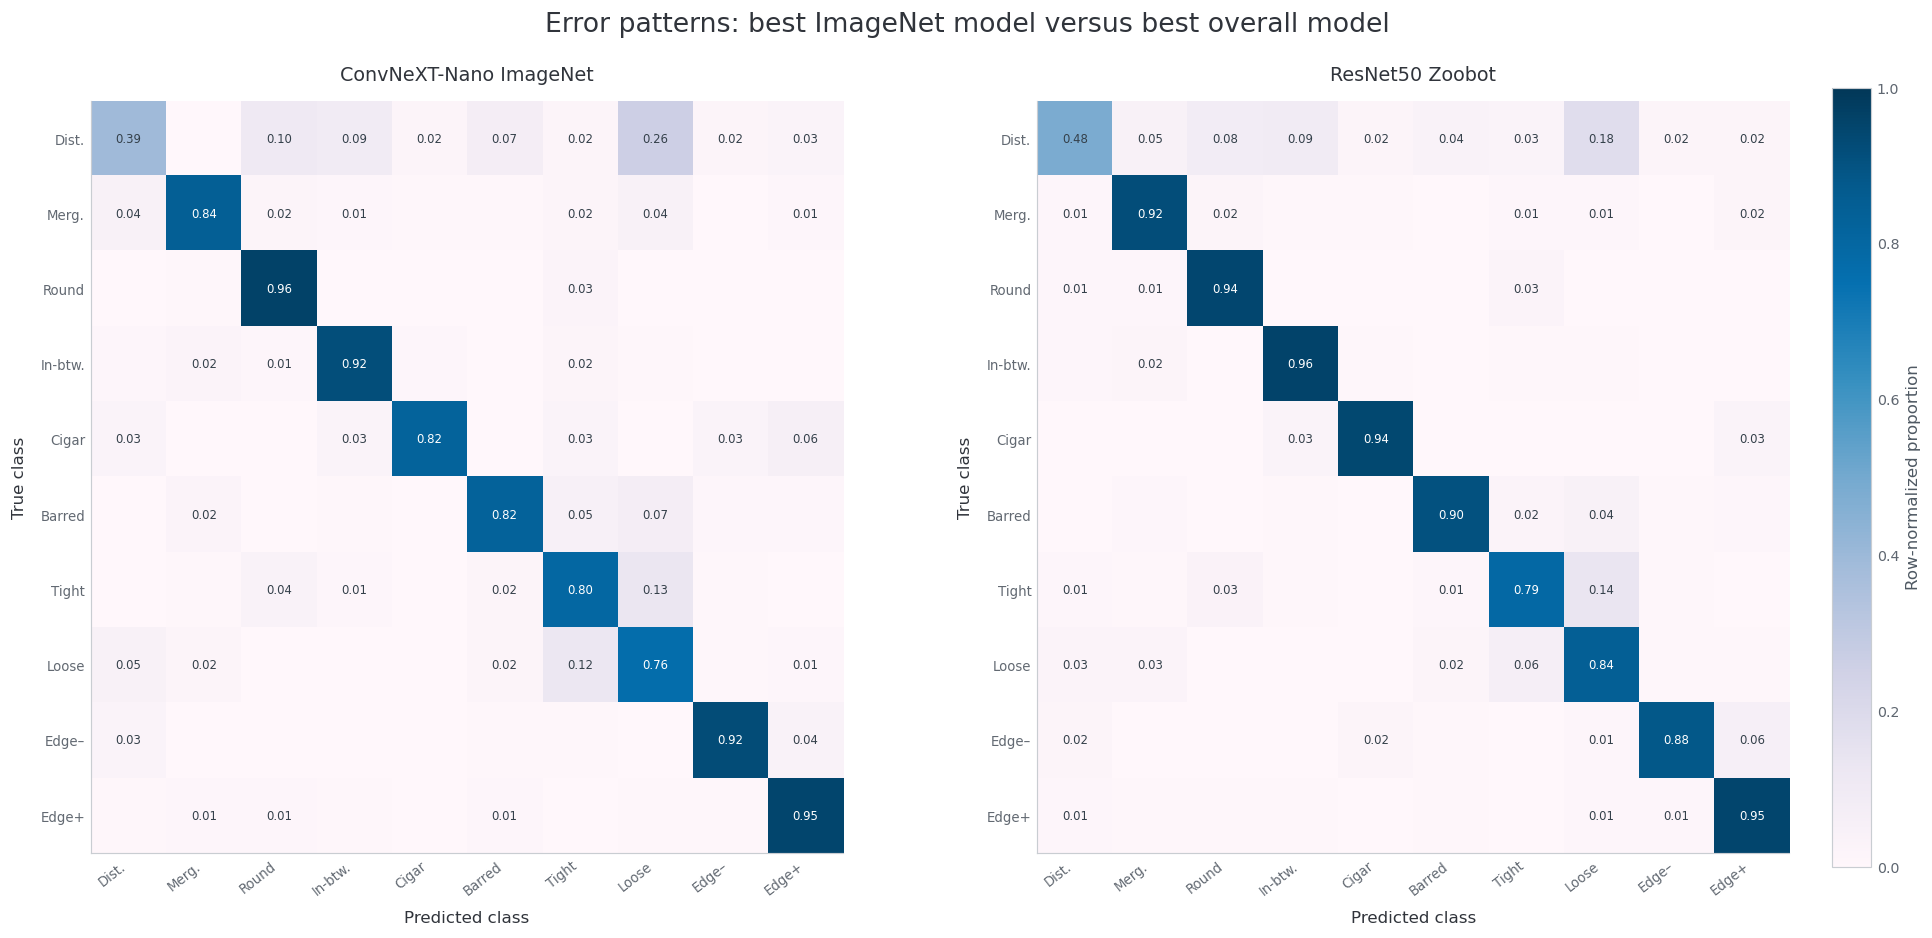

In [22]:
best_imagenet_row = (
    summary_df[
        summary_df["Pretraining"] == "ImageNet"
    ]
    .sort_values(
        "Macro-F1",
        ascending=False,
    )
    .iloc[0]
)

best_imagenet_key = best_imagenet_row[
    "Model Key"
]

best_imagenet_name = best_imagenet_row[
    "Model"
]

comparison_models = [
    (
        best_imagenet_key,
        best_imagenet_name,
    ),
    (
        best_model_key,
        best_model_name,
    ),
]

figure, axes = plt.subplots(
    1,
    2,
    figsize=(16, 8),
    constrained_layout=True,
    gridspec_kw={
        "wspace": 0.12,
    },
)

for axis, (model_key, model_name) in zip(
    axes,
    comparison_models,
):
    confusion = np.asarray(
        results[model_key]["confusion_matrix"],
        dtype=float,
    )

    row_sums = confusion.sum(
        axis=1,
        keepdims=True,
    )

    normalized_confusion = np.divide(
        confusion,
        row_sums,
        out=np.zeros_like(confusion),
        where=row_sums != 0,
    )

    image = axis.imshow(
        normalized_confusion,
        cmap="PuBu",
        vmin=0,
        vmax=1,
        aspect="equal",
    )

    axis.set_title(
        model_name,
        pad=12,
        fontsize=11.5,
        fontweight="normal",
        color="#30343B",
    )

    axis.set_xlabel(
        "Predicted class",
        labelpad=8,
    )
    axis.set_ylabel(
        "True class",
        labelpad=8,
    )

    axis.set_xticks(
        range(len(SHORT_CLASS_NAMES))
    )
    axis.set_yticks(
        range(len(SHORT_CLASS_NAMES))
    )

    axis.set_xticklabels(
        SHORT_CLASS_NAMES,
        rotation=38,
        ha="right",
        fontsize=8,
    )

    axis.set_yticklabels(
        SHORT_CLASS_NAMES,
        fontsize=8,
    )

    axis.tick_params(
        axis="both",
        length=0,
    )

    for row_index in range(
        normalized_confusion.shape[0]
    ):
        for column_index in range(
            normalized_confusion.shape[1]
        ):
            value = normalized_confusion[
                row_index,
                column_index
            ]

            if value < 0.01:
                continue

            text_colour = (
                "white"
                if value >= 0.55
                else "#34404A"
            )

            axis.text(
                column_index,
                row_index,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color=text_colour,
            )

colour_bar = figure.colorbar(
    image,
    ax=axes,
    location="right",
    shrink=0.82,
    pad=0.025,
)

colour_bar.set_label(
    "Row-normalized proportion",
    color="#4F5963",
)

colour_bar.ax.tick_params(
    length=0,
    labelsize=8.5,
    colors="#5E6670",
)

figure.suptitle(
    "Error patterns: best ImageNet model versus best overall model",
    x=0.5,
    y=0.985,
    ha="center",
    fontsize=16,
    fontweight="normal",
    color="#30343B",
)

plt.savefig(
    FIGURE_DIR
    / "best_imagenet_vs_best_overall_confusion.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

,Model Key,Model,Correct Disturbed,Disturbed → Loose Spiral,Disturbed → Other,Disturbed Support
0,simplecnn,SimpleCNN,0.0000,0.4722,0.5278,108
1,vgg16,VGG16,0.3241,0.2593,0.4167,108
2,densenet121,DenseNet121,0.3611,0.1759,0.4630,108
3,resnet50_imagenet,ResNet50\nImageNet,0.3981,0.1852,0.4167,108
4,resnet50_zoobot,ResNet50\nZoobot,0.4815,0.1759,0.3426,108
5,convnext_nano_imagenet,ConvNeXT-Nano\nImageNet,0.3889,0.2593,0.3519,108
6,convnext_nano_zoobot,ConvNeXT-Nano\nZoobot,0.4907,0.1389,0.3704,108


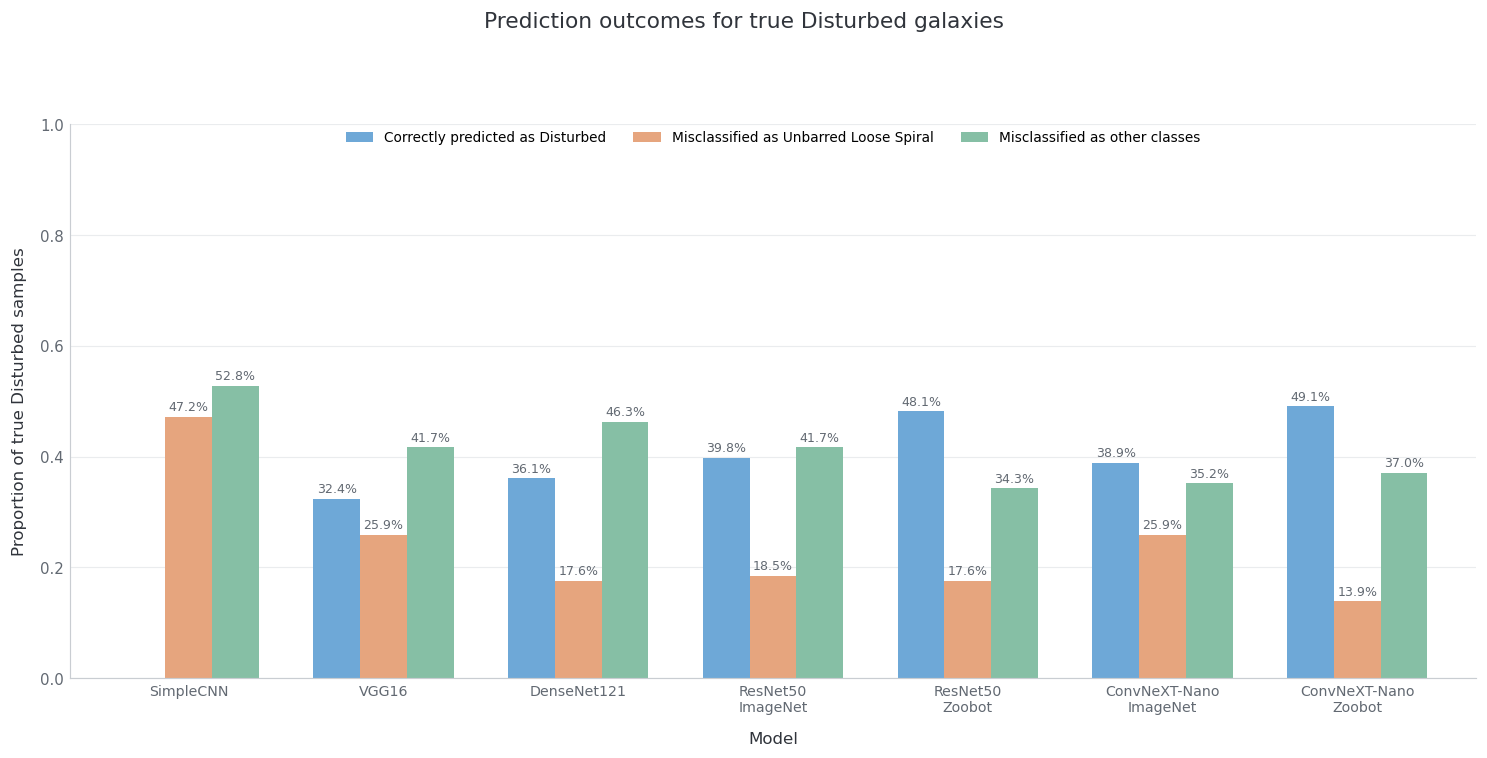

Saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\figures\disturbed_prediction_outcomes.png


In [23]:
DISTURBED_INDEX = CLASS_NAMES.index(
    "Disturbed"
)

LOOSE_SPIRAL_INDEX = CLASS_NAMES.index(
    "Unbarred Loose Spiral"
)

DISTURBED_MODEL_LABELS = {
    "simplecnn": "SimpleCNN",
    "vgg16": "VGG16",
    "densenet121": "DenseNet121",
    "resnet50_imagenet": "ResNet50\nImageNet",
    "resnet50_zoobot": "ResNet50\nZoobot",
    "convnext_nano_imagenet": (
        "ConvNeXT-Nano\nImageNet"
    ),
    "convnext_nano_zoobot": (
        "ConvNeXT-Nano\nZoobot"
    ),
}

disturbed_error_rows = []

for model_key in ALL_MODEL_KEYS:
    confusion = np.asarray(
        results[model_key]["confusion_matrix"],
        dtype=float,
    )

    disturbed_row = confusion[
        DISTURBED_INDEX
    ]

    disturbed_total = disturbed_row.sum()

    if disturbed_total <= 0:
        raise ValueError(
            f"{model_key} has no true Disturbed samples."
        )

    correct_rate = (
        disturbed_row[DISTURBED_INDEX]
        / disturbed_total
    )

    loose_spiral_rate = (
        disturbed_row[LOOSE_SPIRAL_INDEX]
        / disturbed_total
    )

    other_error_rate = (
        1.0
        - correct_rate
        - loose_spiral_rate
    )

    disturbed_error_rows.append(
        {
            "Model Key": model_key,
            "Model": DISTURBED_MODEL_LABELS[
                model_key
            ],
            "Correct Disturbed": correct_rate,
            "Disturbed → Loose Spiral": (
                loose_spiral_rate
            ),
            "Disturbed → Other": (
                other_error_rate
            ),
            "Disturbed Support": int(
                disturbed_total
            ),
        }
    )

disturbed_error_df = pd.DataFrame(
    disturbed_error_rows
)

display(
    disturbed_error_df.round(4)
)

plot_data = disturbed_error_df.set_index(
    "Model"
)[
    [
        "Correct Disturbed",
        "Disturbed → Loose Spiral",
        "Disturbed → Other",
    ]
]

axis = plot_data.plot(
    kind="bar",
    figsize=(12.5, 6.5),
    width=0.72,
    color=METRIC_COLOURS,
    edgecolor="none",
)

figure = axis.get_figure()

axis.set_title("")

figure.suptitle(
    "Prediction outcomes for true Disturbed galaxies",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color=PALETTE["text"],
)

axis.set_xlabel(
    "Model",
    labelpad=10,
)

axis.set_ylabel(
    "Proportion of true Disturbed samples",
    labelpad=8,
)

axis.set_ylim(
    0,
    1,
)

axis.tick_params(
    axis="x",
    rotation=0,
    length=0,
)

axis.tick_params(
    axis="y",
    length=0,
)

axis.grid(
    axis="y",
    color=PALETTE["grid"],
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

for label in axis.get_xticklabels():
    label.set_color(
        PALETTE["muted_text"]
    )
    label.set_fontsize(8.5)

axis.legend(
    title=None,
    labels=[
        "Correctly predicted as Disturbed",
        "Misclassified as Unbarred Loose Spiral",
        "Misclassified as other classes",
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=False,
    fontsize=8.2,
)

for container in axis.containers:
    axis.bar_label(
        container,
        labels=[
            f"{value:.1%}"
            if value >= 0.025
            else ""
            for value in container.datavalues
        ],
        padding=2,
        fontsize=7.5,
        color=PALETTE["muted_text"],
    )

plt.tight_layout(
    rect=[0, 0, 1, 0.90]
)

disturbed_error_path = (
    FIGURE_DIR
    / "disturbed_prediction_outcomes.png"
)

figure.savefig(
    disturbed_error_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved to: {disturbed_error_path}"
)

In [24]:
import torch
from torch.utils.data import DataLoader

from src.baseline.train_baseline import (
    BATCH_SIZE,
    DEVICE,
    NUM_WORKERS,
    SEED,
    build_transforms,
)
from src.evaluation.gradcam import (
    load_trained_model,
    tensor_to_image,
)
from src.preprocessing.dataloader import (
    build_dataloaders,
)


DISTURBED_INDEX = CLASS_NAMES.index(
    "Disturbed"
)

LOOSE_SPIRAL_INDEX = CLASS_NAMES.index(
    "Unbarred Loose Spiral"
)


_, evaluation_transform = build_transforms()

_, _, original_test_loader = build_dataloaders(
    batch_size=BATCH_SIZE,
    train_ratio=0.8,
    val_ratio=0.1,
    test_ratio=0.1,
    random_state=SEED,
    num_workers=NUM_WORKERS,
    train_transform=evaluation_transform,
    val_transform=evaluation_transform,
    test_transform=evaluation_transform,
)

test_dataset = original_test_loader.dataset


ordered_test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)


analysis_model = load_trained_model(
    best_model_key
)


all_true_labels = []
all_predicted_labels = []
all_confidences = []


analysis_model.eval()

with torch.no_grad():
    for images, labels in ordered_test_loader:
        images = images.to(
            DEVICE
        )

        logits = analysis_model(
            images
        )

        probabilities = torch.softmax(
            logits,
            dim=1,
        )

        confidences, predictions = (
            probabilities.max(dim=1)
        )

        all_true_labels.append(
            labels.cpu().numpy()
        )

        all_predicted_labels.append(
            predictions.cpu().numpy()
        )

        all_confidences.append(
            confidences.cpu().numpy()
        )


all_true_labels = np.concatenate(
    all_true_labels
)

all_predicted_labels = np.concatenate(
    all_predicted_labels
)

all_confidences = np.concatenate(
    all_confidences
)


if len(all_true_labels) != len(test_dataset):
    raise RuntimeError(
        "Prediction count does not match the test-dataset size."
    )


test_sample_indices = np.arange(
    len(test_dataset)
)


correct_disturbed_candidates = (
    test_sample_indices[
        (all_true_labels == DISTURBED_INDEX)
        & (
            all_predicted_labels
            == DISTURBED_INDEX
        )
    ]
)


incorrect_disturbed_candidates = (
    test_sample_indices[
        (all_true_labels == DISTURBED_INDEX)
        & (
            all_predicted_labels
            == LOOSE_SPIRAL_INDEX
        )
    ]
)


correct_loose_candidates = (
    test_sample_indices[
        (
            all_true_labels
            == LOOSE_SPIRAL_INDEX
        )
        & (
            all_predicted_labels
            == LOOSE_SPIRAL_INDEX
        )
    ]
)


print(
    "Best model:",
    best_model_key,
)

print(
    "Correct Disturbed candidates:",
    len(correct_disturbed_candidates),
)

print(
    "Disturbed → Loose Spiral candidates:",
    len(incorrect_disturbed_candidates),
)

print(
    "Correct Loose Spiral candidates:",
    len(correct_loose_candidates),
)

C:\Users\Olivia\.astroNN\datasets\Galaxy10_DECals.h5 was found!


Best model: resnet50_zoobot
Correct Disturbed candidates: 52
Disturbed → Loose Spiral candidates: 19
Correct Loose Spiral candidates: 221


In [25]:
SAMPLES_PER_GROUP = 6
SAMPLE_SELECTION_SEED = 42

selection_rng = np.random.default_rng(
    SAMPLE_SELECTION_SEED
)


def select_sample_indices(
    candidate_indices,
    sample_count,
    group_name,
):
    candidate_indices = np.asarray(
        candidate_indices,
        dtype=int,
    )

    if len(candidate_indices) < sample_count:
        raise ValueError(
            f"{group_name} contains only "
            f"{len(candidate_indices)} samples; "
            f"{sample_count} were requested."
        )

    return np.sort(
        selection_rng.choice(
            candidate_indices,
            size=sample_count,
            replace=False,
        )
    )


selected_correct_disturbed = (
    select_sample_indices(
        correct_disturbed_candidates,
        SAMPLES_PER_GROUP,
        "Correct Disturbed",
    )
)

selected_incorrect_disturbed = (
    select_sample_indices(
        incorrect_disturbed_candidates,
        SAMPLES_PER_GROUP,
        "Disturbed → Loose Spiral",
    )
)

selected_correct_loose = (
    select_sample_indices(
        correct_loose_candidates,
        SAMPLES_PER_GROUP,
        "Correct Loose Spiral",
    )
)


selected_sample_indices = {
    "Correct Disturbed": (
        selected_correct_disturbed
    ),
    "Disturbed → Loose Spiral": (
        selected_incorrect_disturbed
    ),
    "Correct Loose Spiral": (
        selected_correct_loose
    ),
}


sample_selection_rows = []

for group_name, indices in (
    selected_sample_indices.items()
):
    for sample_index in indices:
        sample_selection_rows.append({
            "Group": group_name,
            "Sample Index": int(
                sample_index
            ),
            "True Class": CLASS_NAMES[
                int(
                    all_true_labels[
                        sample_index
                    ]
                )
            ],
            "Predicted Class": CLASS_NAMES[
                int(
                    all_predicted_labels[
                        sample_index
                    ]
                )
            ],
            "Prediction Confidence": float(
                all_confidences[
                    sample_index
                ]
            ),
        })


sample_selection_df = pd.DataFrame(
    sample_selection_rows
)

display(
    sample_selection_df.round(4)
)

,Group,Sample Index,True Class,Predicted Class,Prediction Confidence
0,Correct Disturbed,280,Disturbed,Disturbed,0.9974
1,Correct Disturbed,777,Disturbed,Disturbed,0.9925
2,Correct Disturbed,779,Disturbed,Disturbed,0.9491
3,Correct Disturbed,1061,Disturbed,Disturbed,0.9999
4,Correct Disturbed,1304,Disturbed,Disturbed,0.4754
5,Correct Disturbed,1510,Disturbed,Disturbed,0.4405
6,Disturbed → Loose Spiral,919,Disturbed,Unbarred Loose Spiral,0.8146
7,Disturbed → Loose Spiral,956,Disturbed,Unbarred Loose Spiral,0.9804
8,Disturbed → Loose Spiral,1057,Disturbed,Unbarred Loose Spiral,0.8965
9,Disturbed → Loose Spiral,1102,Disturbed,Unbarred Loose Spiral,0.9655


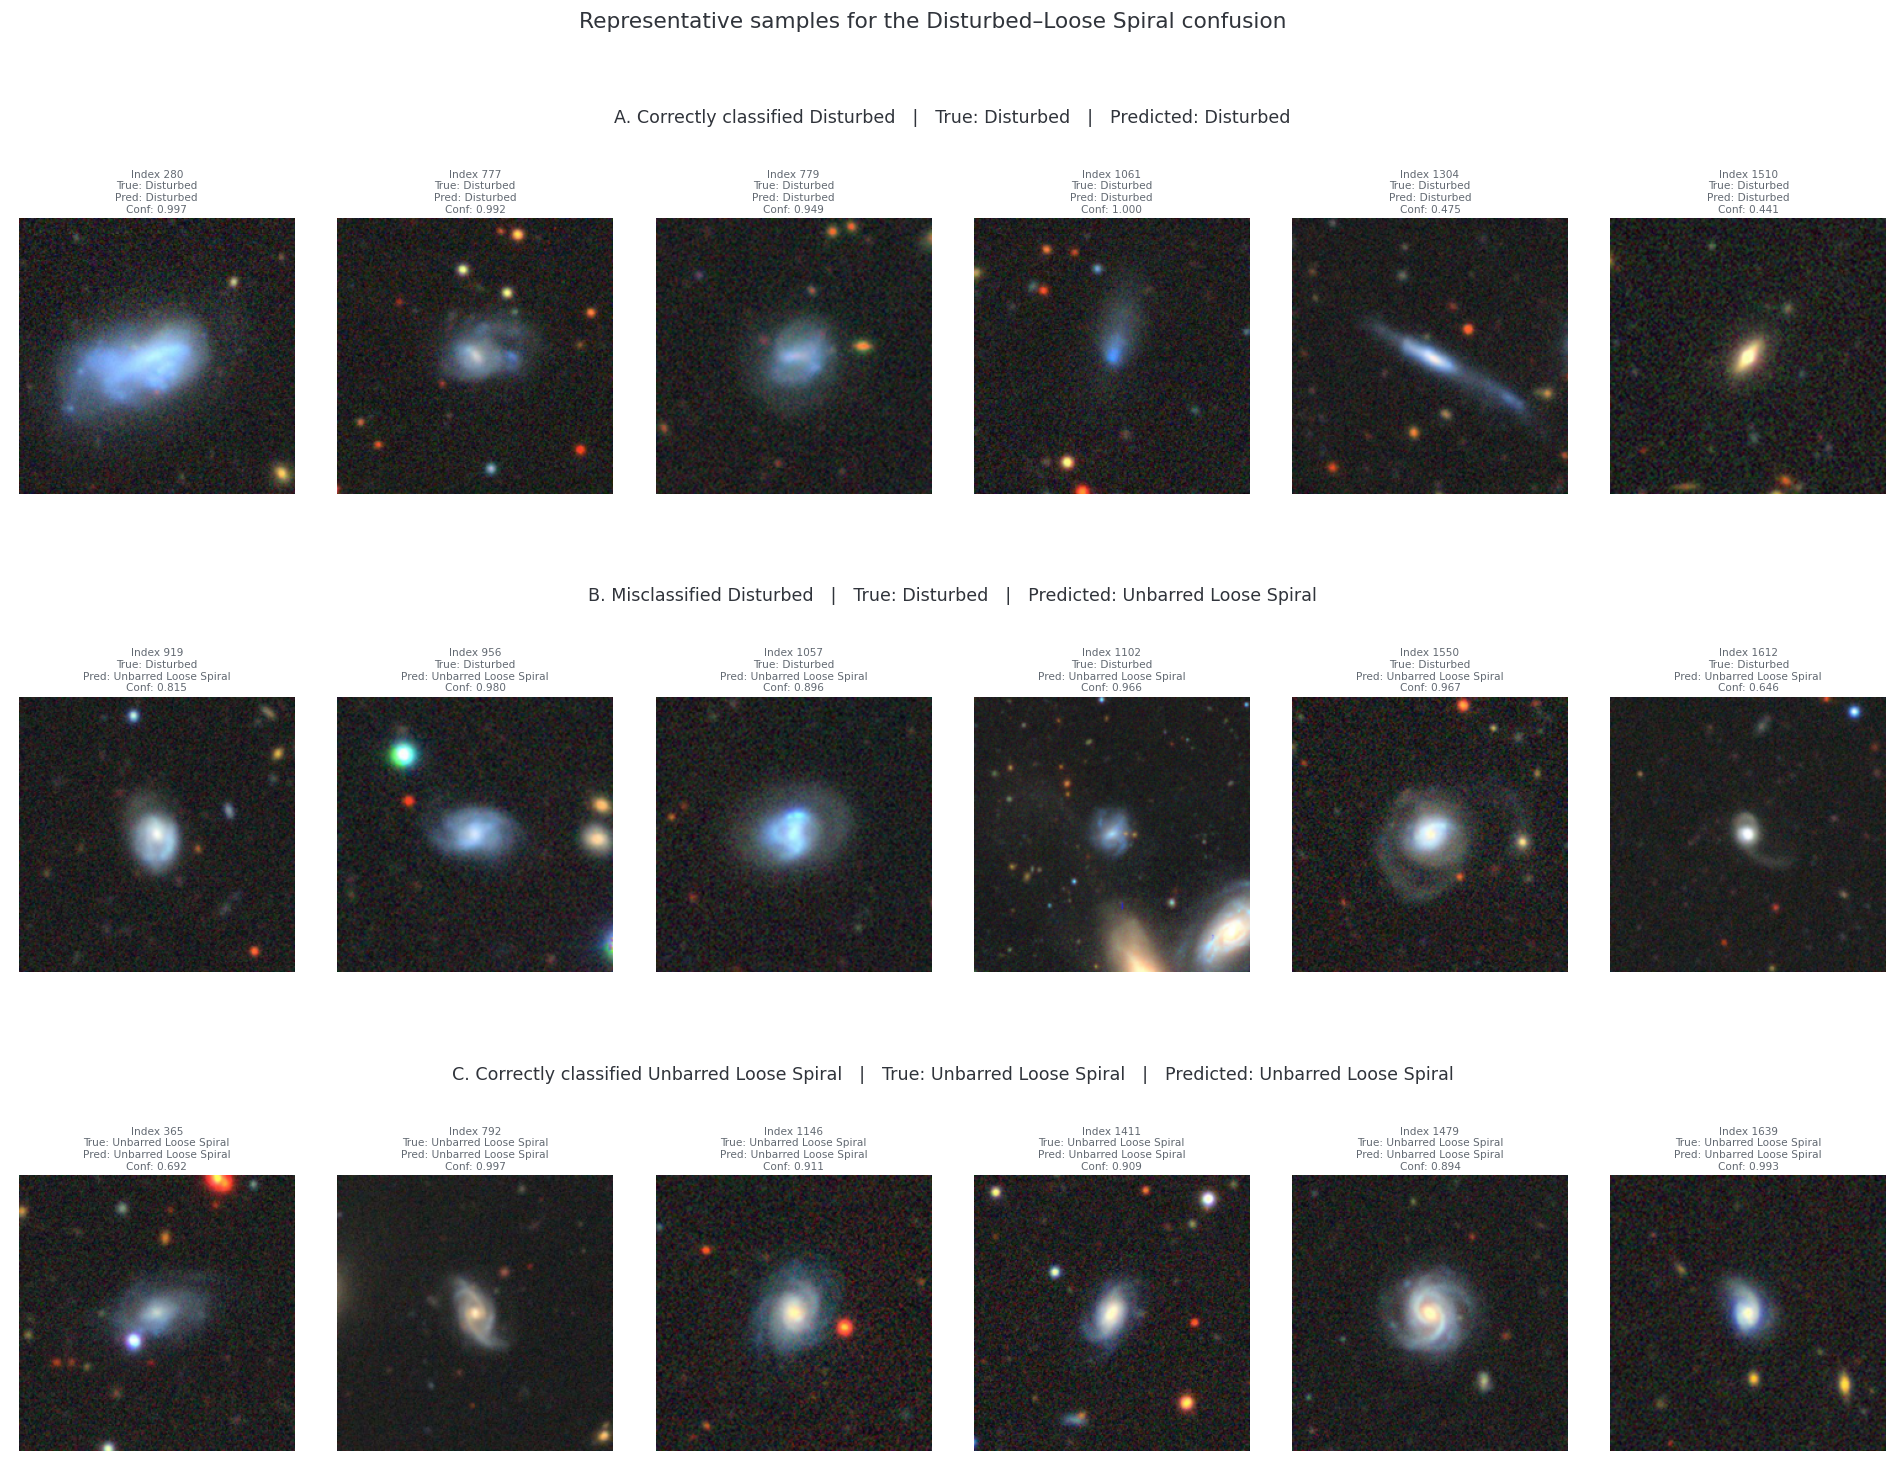

Saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\figures\disturbed_loose_spiral_sample_montage.png


In [26]:
from matplotlib.gridspec import GridSpec


group_definitions = [
    {
        "title": (
            "A. Correctly classified Disturbed"
            "   |   True: Disturbed"
            "   |   Predicted: Disturbed"
        ),
        "indices": selected_correct_disturbed,
    },
    {
        "title": (
            "B. Misclassified Disturbed"
            "   |   True: Disturbed"
            "   |   Predicted: Unbarred Loose Spiral"
        ),
        "indices": selected_incorrect_disturbed,
    },
    {
        "title": (
            "C. Correctly classified Unbarred Loose Spiral"
            "   |   True: Unbarred Loose Spiral"
            "   |   Predicted: Unbarred Loose Spiral"
        ),
        "indices": selected_correct_loose,
    },
]


figure = plt.figure(
    figsize=(16.5, 12.5),
)

grid = GridSpec(
    nrows=6,
    ncols=SAMPLES_PER_GROUP,
    figure=figure,
    height_ratios=[
        0.55,
        1.0,
        0.55,
        1.0,
        0.55,
        1.0,
    ],
    hspace=0.12,
    wspace=0.10,
)


for group_index, group in enumerate(
    group_definitions
):
    title_row = group_index * 2
    image_row = title_row + 1

    title_axis = figure.add_subplot(
        grid[
            title_row,
            :,
        ]
    )

    title_axis.text(
        0.5,
        0.5,
        group["title"],
        ha="center",
        va="center",
        fontsize=10.5,
        fontweight="normal",
        color=PALETTE["text"],
    )

    title_axis.axis(
        "off"
    )

    for column_index, sample_index in enumerate(
        group["indices"]
    ):
        axis = figure.add_subplot(
            grid[
                image_row,
                column_index,
            ]
        )

        image_tensor, true_label = (
            test_dataset[
                int(sample_index)
            ]
        )

        display_image = tensor_to_image(
            image_tensor.unsqueeze(0)
        )

        predicted_label = int(
            all_predicted_labels[
                sample_index
            ]
        )

        confidence = float(
            all_confidences[
                sample_index
            ]
        )

        axis.imshow(
            display_image
        )

        axis.set_title(
            f"Index {sample_index}\n"
            f"True: {CLASS_NAMES[int(true_label)]}\n"
            f"Pred: {CLASS_NAMES[predicted_label]}\n"
            f"Conf: {confidence:.3f}",
            fontsize=6.3,
            fontweight="normal",
            color=PALETTE["muted_text"],
            pad=4,
        )

        axis.axis(
            "off"
        )


figure.suptitle(
    "Representative samples for the "
    "Disturbed–Loose Spiral confusion",
    x=0.5,
    y=0.985,
    fontsize=13,
    fontweight="normal",
    color=PALETTE["text"],
)


figure.subplots_adjust(
    left=0.035,
    right=0.985,
    top=0.965,
    bottom=0.025,
)


sample_montage_path = (
    FIGURE_DIR
    / "disturbed_loose_spiral_sample_montage.png"
)

figure.savefig(
    sample_montage_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved to: {sample_montage_path}"
)

In [27]:
gradcam_sample_indices = {
    "Correct Disturbed": int(
        selected_correct_disturbed[0]
    ),
    "Disturbed → Loose Spiral": int(
        selected_incorrect_disturbed[0]
    ),
    "Correct Loose Spiral": int(
        selected_correct_loose[0]
    ),
}

gradcam_sample_indices

{'Correct Disturbed': 280,
 'Disturbed → Loose Spiral': 919,
 'Correct Loose Spiral': 365}


Correct Disturbed: test sample 280
C:\Users\Olivia\.astroNN\datasets\Galaxy10_DECals.h5 was found!


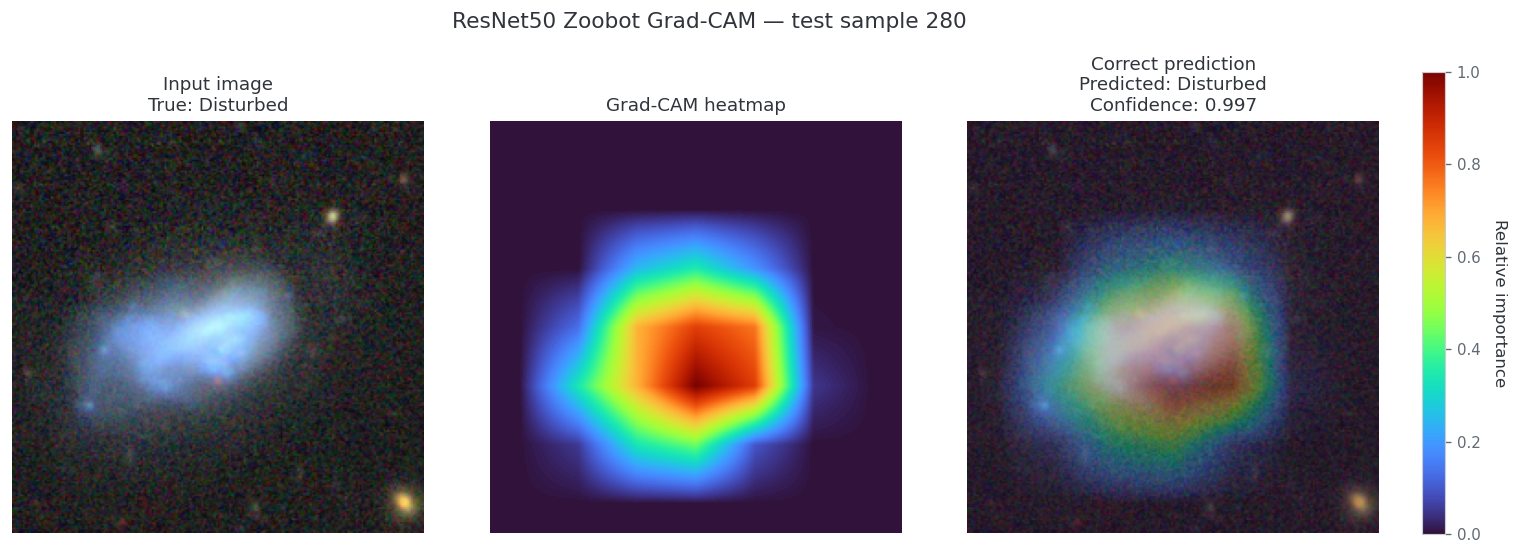


Disturbed → Loose Spiral: test sample 919
C:\Users\Olivia\.astroNN\datasets\Galaxy10_DECals.h5 was found!


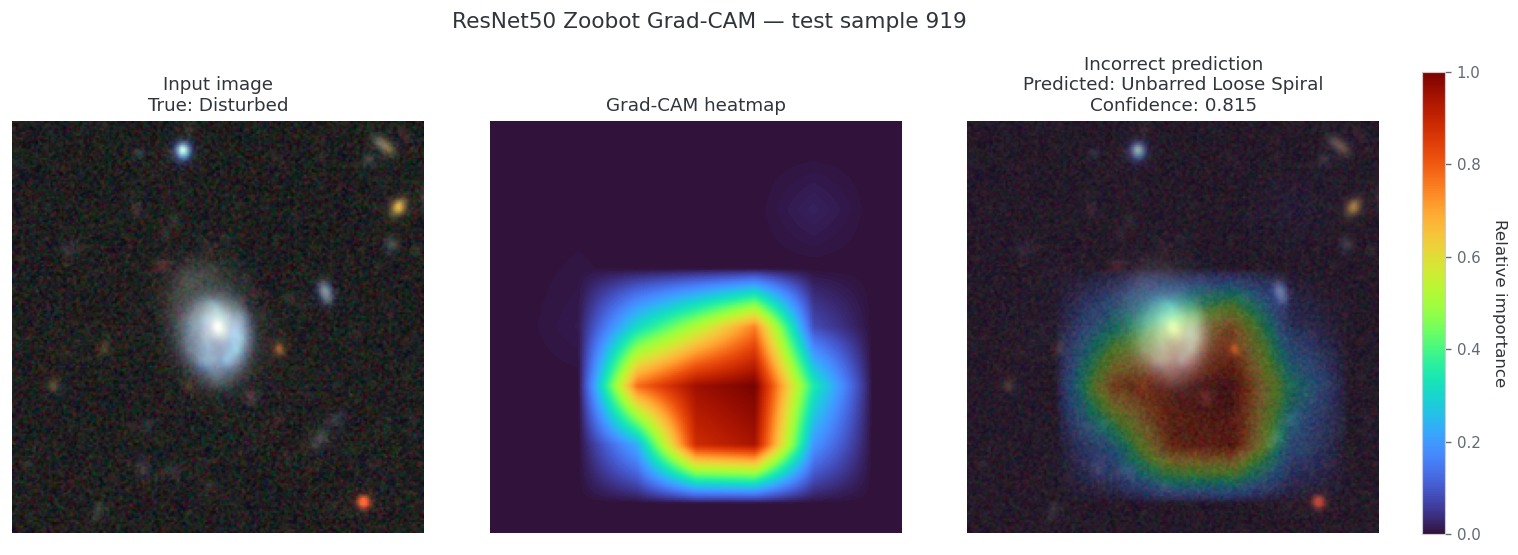


Correct Loose Spiral: test sample 365
C:\Users\Olivia\.astroNN\datasets\Galaxy10_DECals.h5 was found!


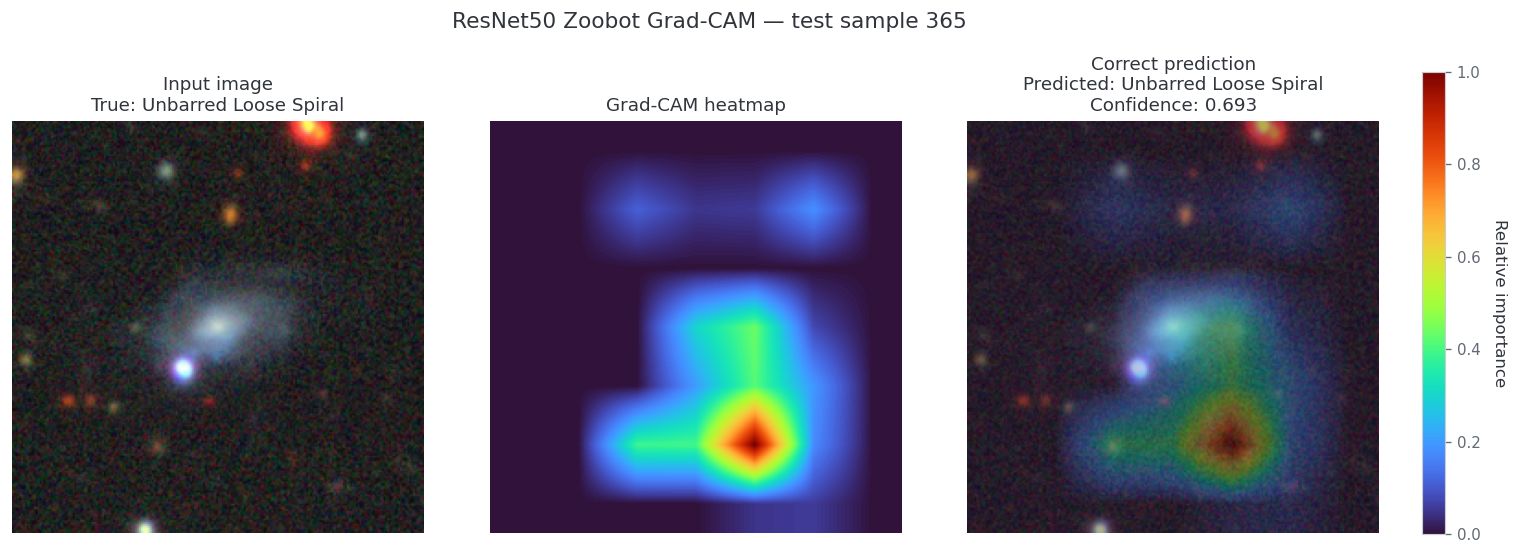

,Group,Model,Sample Index,True Class,Predicted Class,Prediction Confidence,Grad-CAM Target,Correct,Output Path
0,Correct Disturbed,resnet50_zoobot,280,Disturbed,Disturbed,0.997396,Disturbed,True,C:\Users\Olivia\Desktop\COMP9444\Project\COMP9...
1,Disturbed → Loose Spiral,resnet50_zoobot,919,Disturbed,Unbarred Loose Spiral,0.814692,Unbarred Loose Spiral,False,C:\Users\Olivia\Desktop\COMP9444\Project\COMP9...
2,Correct Loose Spiral,resnet50_zoobot,365,Unbarred Loose Spiral,Unbarred Loose Spiral,0.692937,Unbarred Loose Spiral,True,C:\Users\Olivia\Desktop\COMP9444\Project\COMP9...


In [28]:
from IPython.display import display
from src.evaluation.gradcam import (
    generate_gradcam,
)


gradcam_comparison_results = []


for group_name, sample_index in (
    gradcam_sample_indices.items()
):
    print(
        f"\n{group_name}: "
        f"test sample {sample_index}"
    )

    result = generate_gradcam(
        model_name=best_model_key,
        sample_index=sample_index,
        target_class=None,
        save=True,
        return_figure=True,
    )

    display(
        result["figure"]
    )

    gradcam_comparison_results.append({
        "Group": group_name,
        "Model": result[
            "model_name"
        ],
        "Sample Index": result[
            "sample_index"
        ],
        "True Class": result[
            "true_class"
        ],
        "Predicted Class": result[
            "predicted_class"
        ],
        "Prediction Confidence": result[
            "predicted_confidence"
        ],
        "Grad-CAM Target": result[
            "target_class"
        ],
        "Correct": result[
            "correct"
        ],
        "Output Path": str(
            result[
                "output_path"
            ]
        ),
    })

    plt.close(
        result["figure"]
    )


gradcam_comparison_df = pd.DataFrame(
    gradcam_comparison_results
)

display(
    gradcam_comparison_df
)

In [29]:
SUMMARY_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "summary"
)

SUMMARY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

summary_df.to_csv(
    SUMMARY_DIR / "all_models_summary.csv",
    index=False,
)

per_class_df.to_csv(
    SUMMARY_DIR / "per_class_metrics.csv",
    index=False,
)

pretraining_ablation_df.to_csv(
    SUMMARY_DIR / "pretraining_ablation.csv",
    index=False,
)

pretraining_gain_df.to_csv(
    SUMMARY_DIR / "pretraining_per_class_gain.csv",
    index=True,
)

disturbed_error_df.to_csv(
    SUMMARY_DIR / "disturbed_prediction_outcomes.csv",
    index=False,
)

sample_selection_df.to_csv(
    SUMMARY_DIR / "disturbed_sample_selection.csv",
    index=False,
)

gradcam_comparison_df.to_csv(
    SUMMARY_DIR / "disturbed_gradcam_comparison.csv",
    index=False,
)

print(
    "All-model summary saved to:",
    SUMMARY_DIR / "all_models_summary.csv",
)

print(
    "Per-class metrics saved to:",
    SUMMARY_DIR / "per_class_metrics.csv",
)

print(
    "Pretraining ablation saved to:",
    SUMMARY_DIR / "pretraining_ablation.csv",
)

print(
    "Per-class pretraining gain saved to:",
    SUMMARY_DIR / "pretraining_per_class_gain.csv",
)
print(
    "Disturbed prediction outcomes saved to:",
    SUMMARY_DIR / "disturbed_prediction_outcomes.csv",
)

print(
    "Disturbed sample selection saved to:",
    SUMMARY_DIR / "disturbed_sample_selection.csv",
)

print(
    "Disturbed Grad-CAM comparison saved to:",
    SUMMARY_DIR / "disturbed_gradcam_comparison.csv",
)

All-model summary saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\summary\all_models_summary.csv
Per-class metrics saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\summary\per_class_metrics.csv
Pretraining ablation saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\summary\pretraining_ablation.csv
Per-class pretraining gain saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\summary\pretraining_per_class_gain.csv
Disturbed prediction outcomes saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\summary\disturbed_prediction_outcomes.csv
Disturbed sample selection saved to: c:\Users\Olivia\Desktop\COMP9444\Project\COMP9444-Galaxy-Morphology-Classification\outputs\summary\disturbed_sample_selection.csv
Disturbed Grad-CAM comparison saved to: